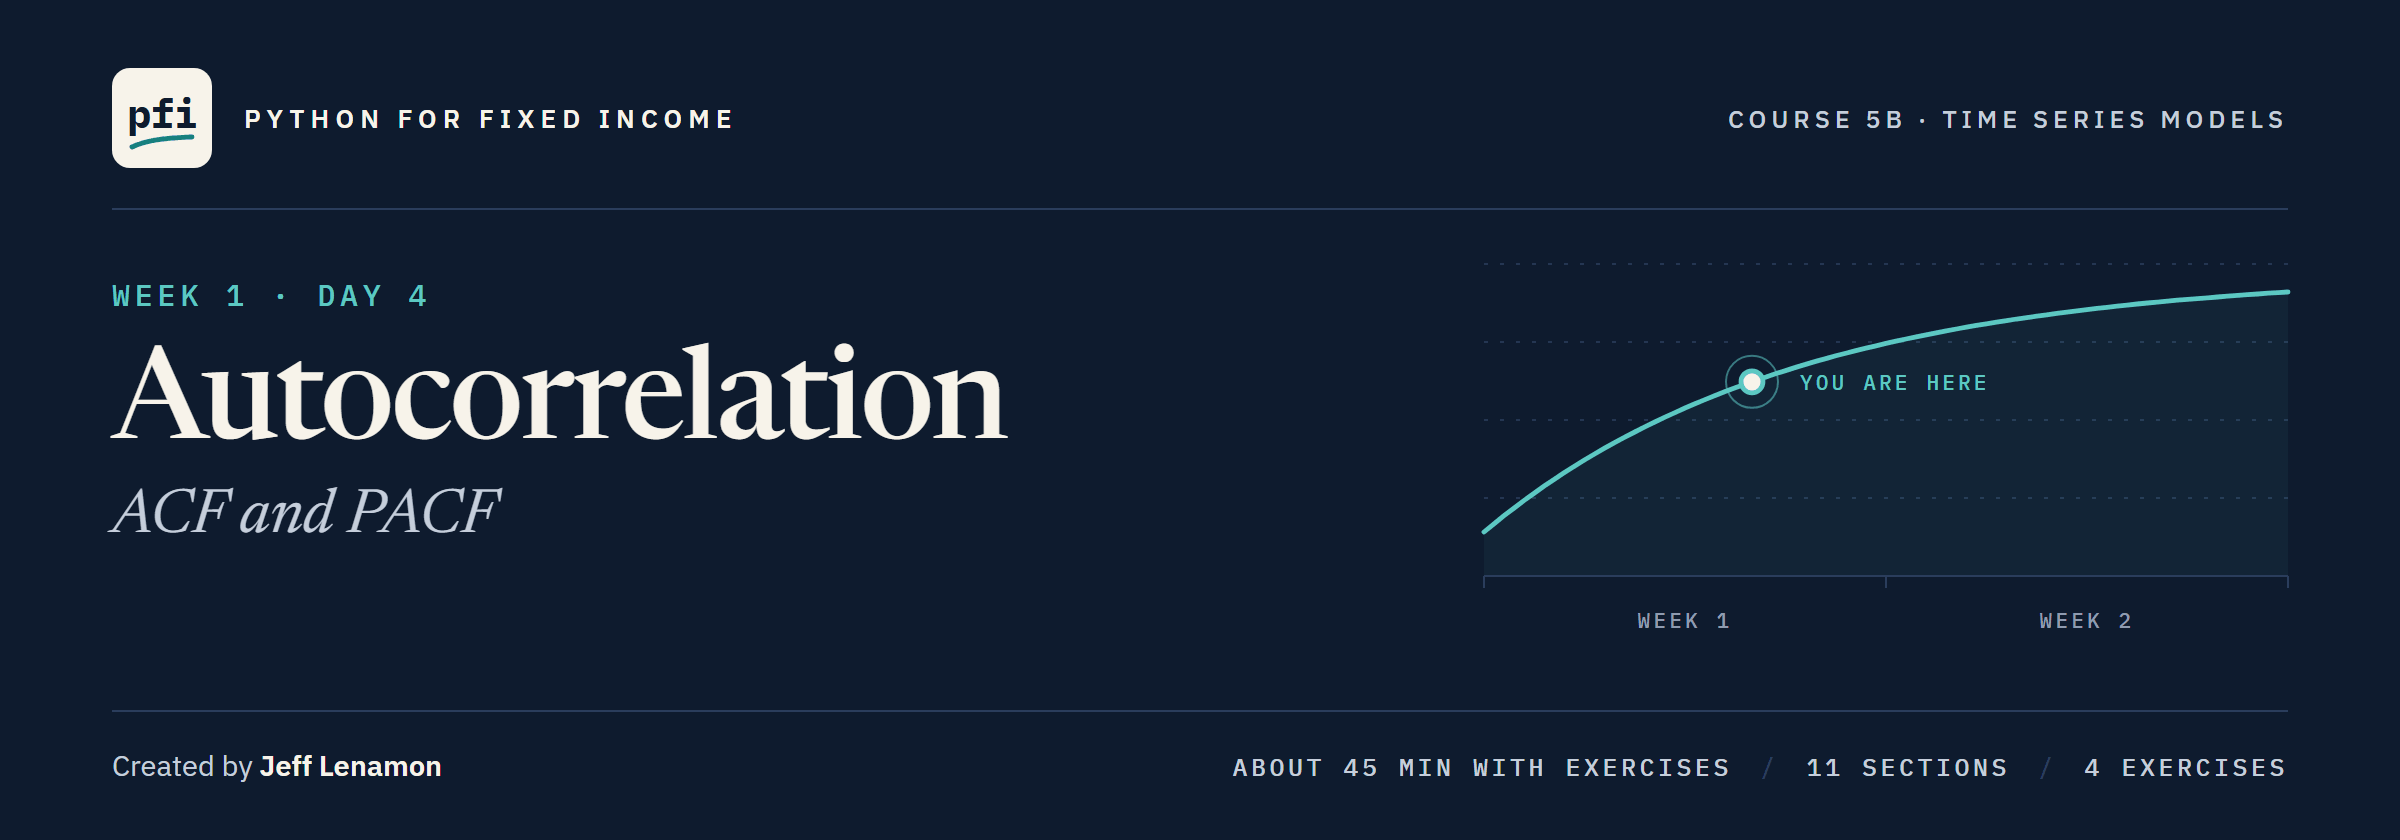

# Autocorrelation: ACF and PACF

Week 1, Day 4. Measure how much a daily change remembers of the days before it, decide which autocorrelations count, and read the pictures that name a model's order.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day4/04_autocorrelation_acf_and_pacf.ipynb)

# Problem Statement

## Business Context

Course 4's Day 11 drew the correlogram of a daily yield change and found it near zero at every lag.
Day 5 fits AR and ARIMA models to the five series' daily changes, and it needs two answers first.
Is there any memory in the changes worth a model, and if there is, how many lags back does it reach?
Today reads that memory on the development years, sets how large an autocorrelation must be to count, and draws the pictures that name a model's order.
A test fits nothing to score, so we read all of the development years; the held-out years stay closed.

## Objectives

Compute an autocorrelation by hand and with statsmodels, draw an ACF with its confidence band, and measure what noise alone puts outside the band.
Read the ACF of a series' changes and of their squares, compute a partial autocorrelation as a regression coefficient, and read the identification grid to name an AR or MA order.
Run the Ljung-Box test by hand and with statsmodels, and check whether an autocorrelation holds across windows of the development years.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, 2015-01-02 to 2026-10-02
2. `2 Yr`, `10 Yr`: par yields, percent (the other twelve tenors are not used today)

`course3_synthetic_spreads.csv`, one row per trading day of the Treasury file:

1. `ig_spread_bp`, `hy_spread_bp`: investment grade and high yield spreads, bp

Made in the notebook, as on Day 2: the five series in bp (`2 Yr`, `10 Yr`, `2s10s`, `IG`, `HY`) on the development years, their daily changes, and simulated series from the seeded generator.

## Your Route Through Day 4

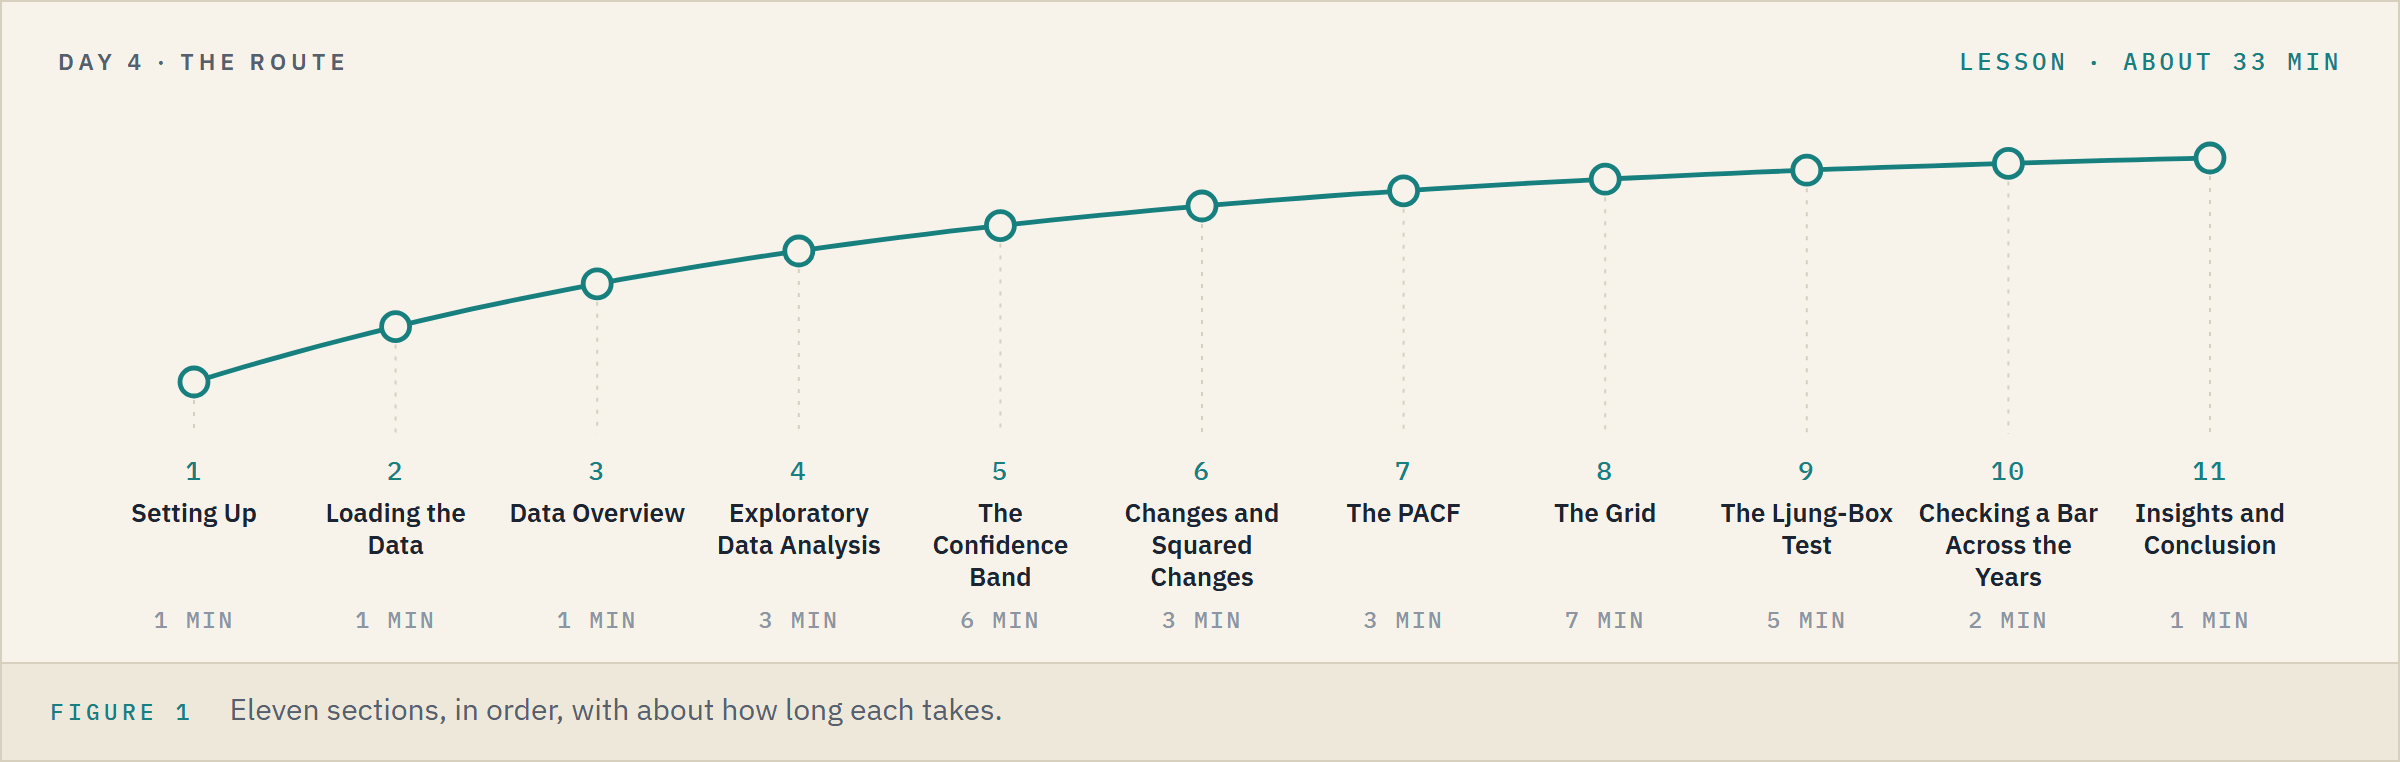

**Time.** About 33 minutes for the lesson, then about 12 for the four exercises.

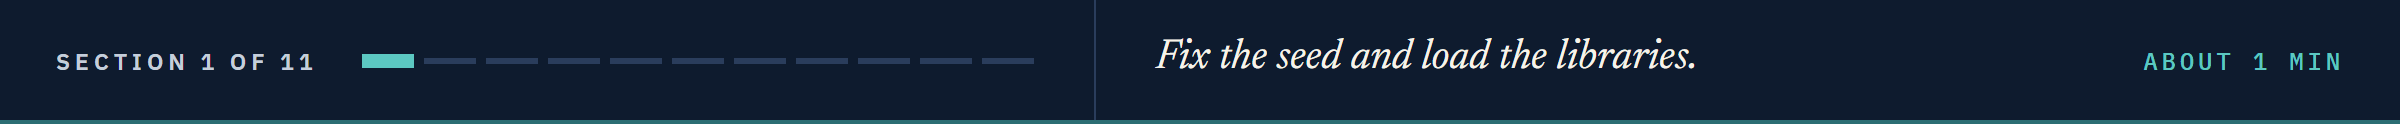

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the autocorrelation, its pictures and its test, and simulated processes, from statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.stats.diagnostic import acorr_ljungbox

# the chi-squared distribution, and Day 2's walk-forward folds
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

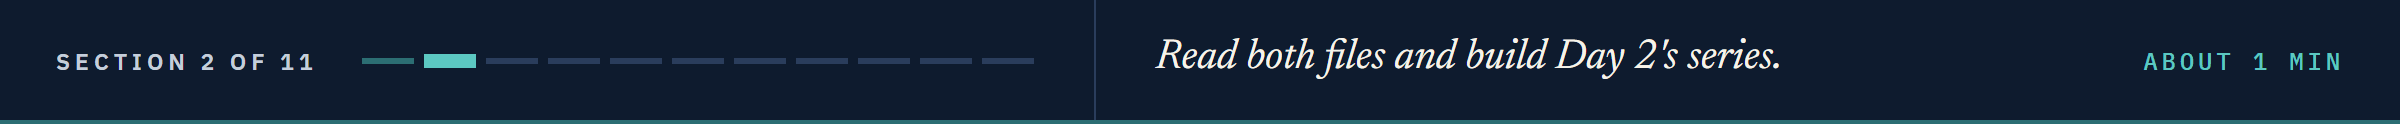

# Loading the Data

## Reading the Two Files

In [3]:
# the Treasury par yields in percent and the synthetic spreads in bp, one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: the development years only, so the held-out years stay closed
CUT = "2022-12-30"
development = yields.loc[:CUT]

## Day 2's Five Series in bp

In [4]:
# Day 2's five series, all in bp: a yield in percent times 100, the slope as 10 Yr less 2 Yr
levels = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# each day's change in bp: the level less the level one row before
changes = levels.diff().dropna()
print(len(levels), "levels and", len(changes), "changes, from", changes.index[0].date(), "to", changes.index[-1].date())

2001 levels and 2000 changes, from 2015-01-05 to 2022-12-30


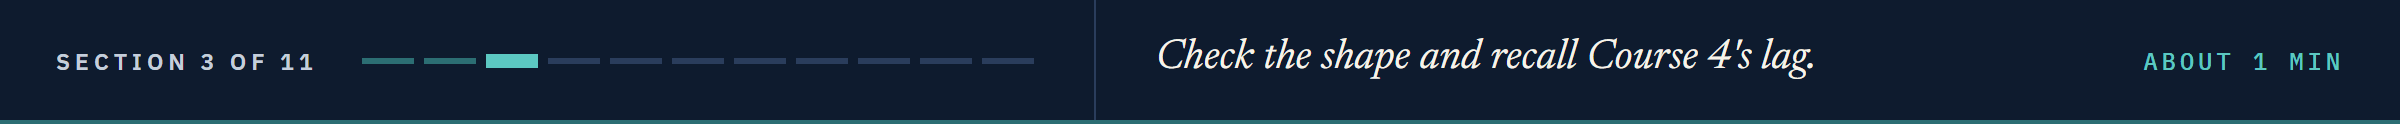

# Data Overview

## Checking the Shape

In [5]:
# rows and columns of the changes, and how many cells are blank
print(changes.shape, "| blank cells:", changes.isna().sum().sum())

(2000, 5) | blank cells: 0


## Recalling Course 4's Lag-1 Correlation

Course 4's Day 11 measured how alike a date is to the date before with `.autocorr(1)`.

In [6]:
# the 10 Yr's level and its daily change, each against itself one row before
print("Level:", round(levels["10 Yr"].autocorr(1), 4), "| Change:", round(changes["10 Yr"].autocorr(1), 4))

Level: 0.9977 | Change: -0.0075


The level is almost a copy of the day before.

The change sits near zero, as Course 4 found.

**The level copies the day before and the change sits near zero. Today finds out how near zero a number must be to count as zero.**

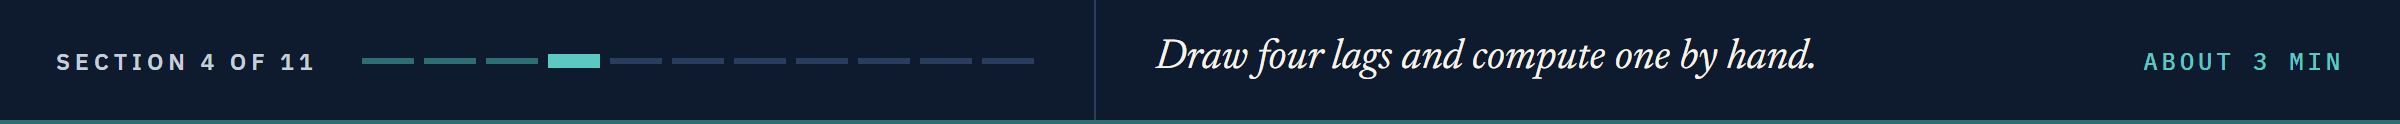

# Exploratory Data Analysis

## The 10 Yr's Change Against Itself at Four Lags

Course 4's lag plot, at four lags instead of one.

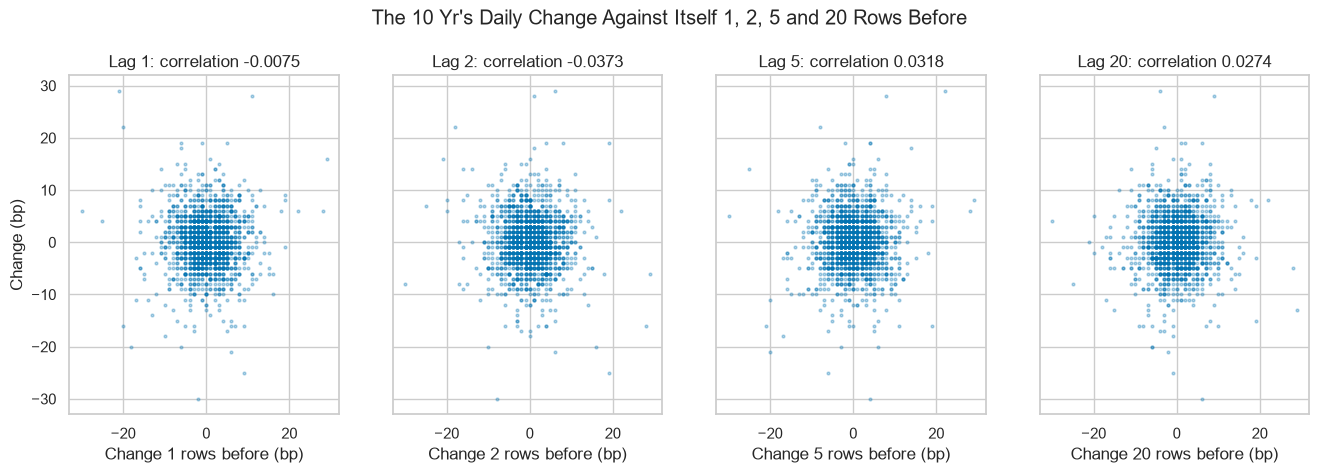

In [7]:
# the 10 Yr's change against itself 1, 2, 5 and 20 rows before, the correlation in each title
ten = changes["10 Yr"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharex=True, sharey=True)
for ax, k in zip(axes, [1, 2, 5, 20]):
    ax.scatter(ten.shift(k), ten, s=4, alpha=0.3)
    ax.set_title(f"Lag {k}: correlation {ten.autocorr(k):.4f}")
    ax.set_xlabel(f"Change {k} rows before (bp)")
axes[0].set_ylabel("Change (bp)")
fig.suptitle("The 10 Yr's Daily Change Against Itself 1, 2, 5 and 20 Rows Before", y=1.03)
plt.show()

Four round clouds with no tilt to the eye.

Four small correlations, two of them negative.

## The Autocorrelation by Hand

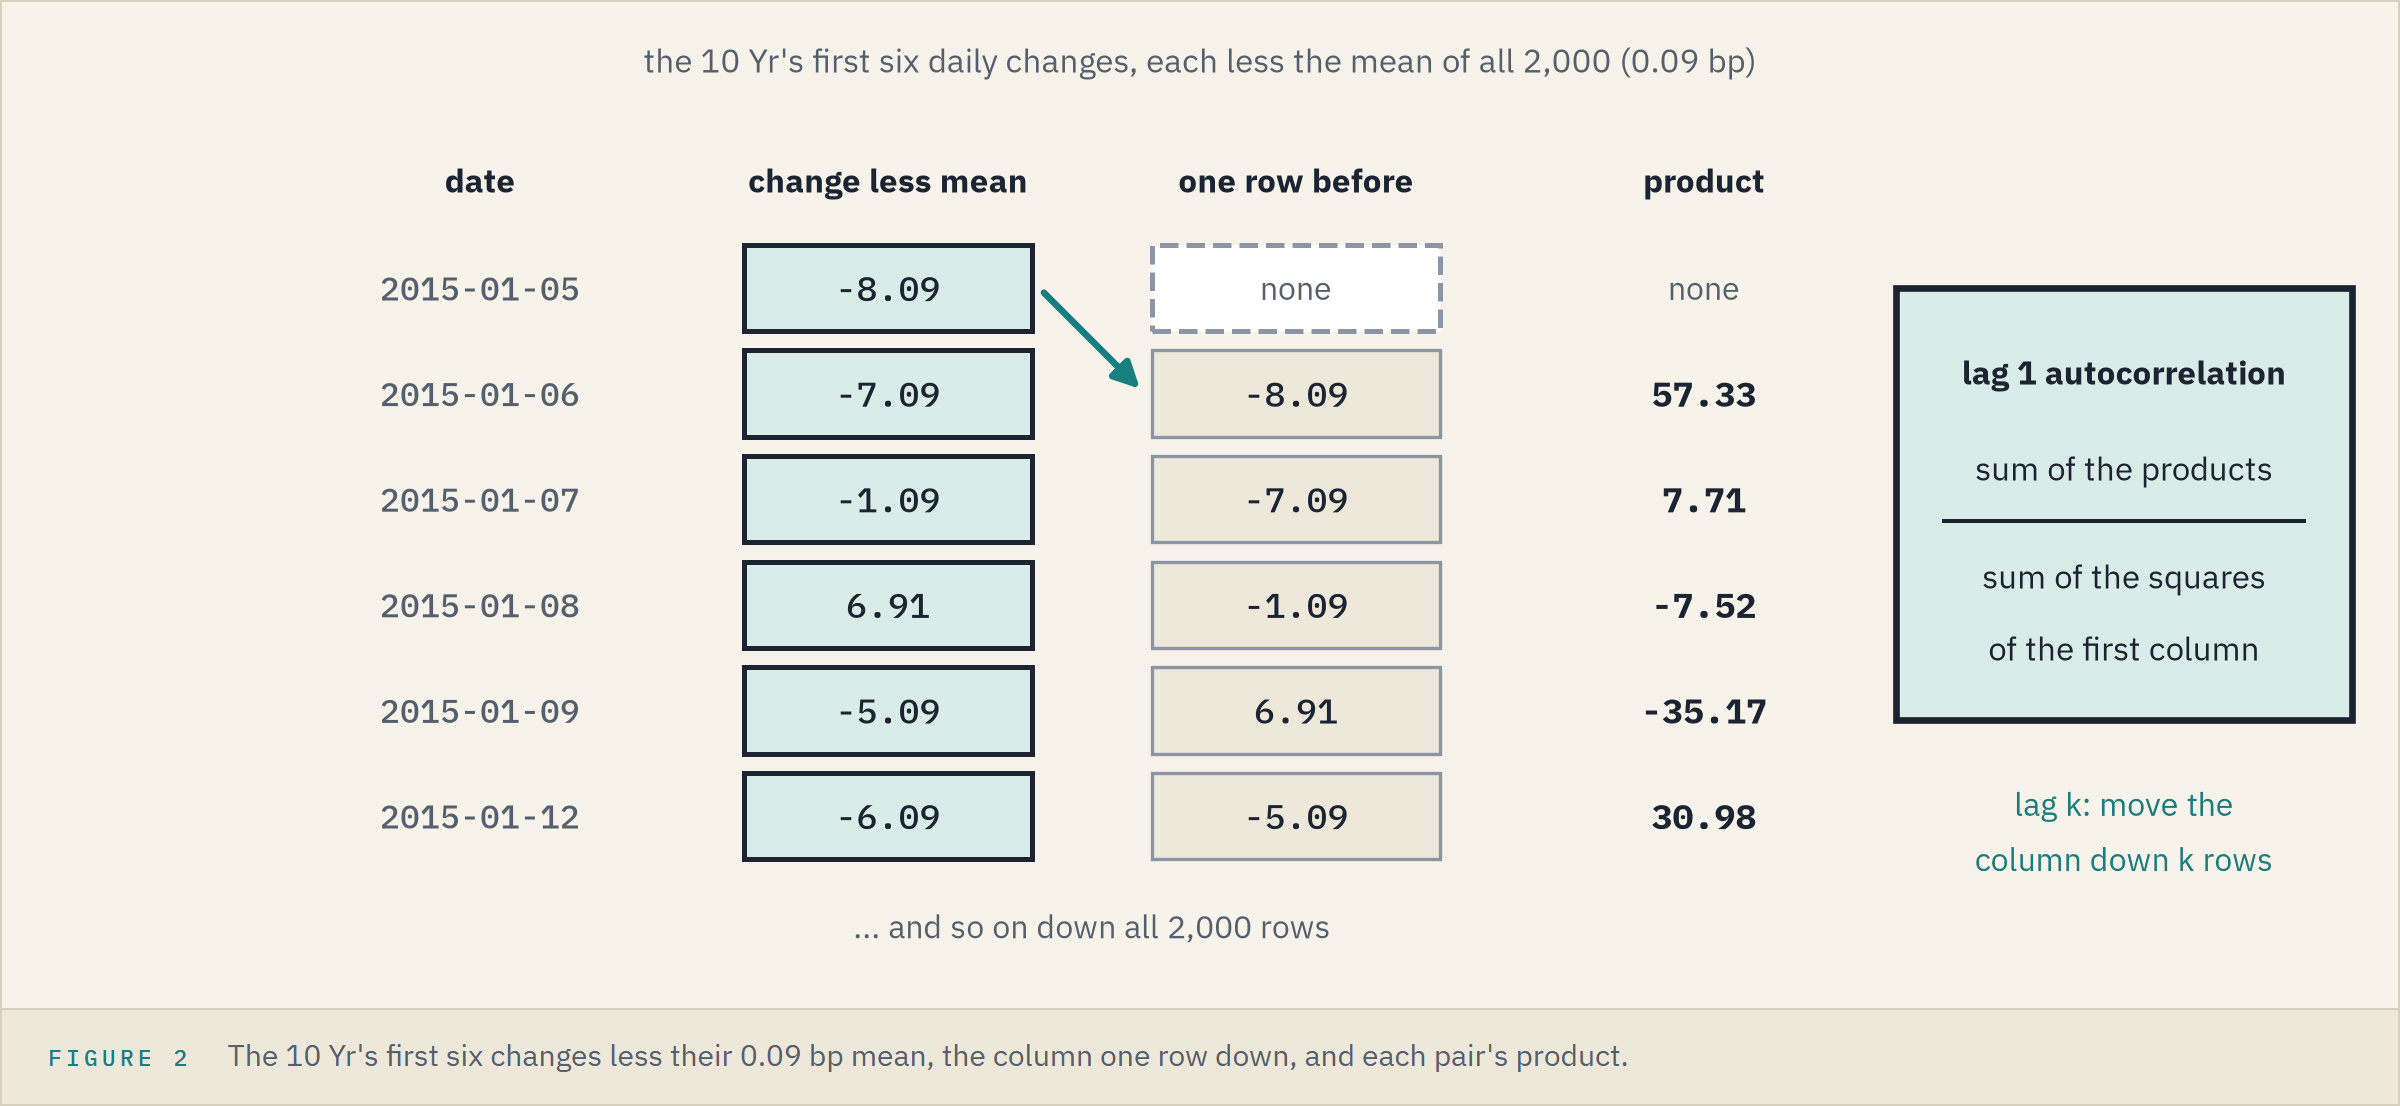

The **autocorrelation** at lag k takes the one mean of the whole column away, multiplies each value by the value k rows before, adds up the products, and divides by the sum of the squares.
The **ACF**, the autocorrelation function, is that number at every lag.
`acf(values, nlags=5)` from statsmodels returns lags 0 to 5; lag 0 is always 1.

In [8]:
# the 10 Yr's changes as a plain array, less their one mean
values = ten.to_numpy()
centred = values - values.mean()

# lags 1 to 5 by hand: the products of each value and the value k rows before, over the sum of squares
by_hand = [np.sum(centred[k:] * centred[:-k]) / np.sum(centred ** 2) for k in range(1, 6)]

In [9]:
# the same five lags by hand, from statsmodels' acf, and from pandas' autocorr
three_ways = pd.DataFrame({"by hand": by_hand, "acf": acf(values, nlags=5)[1:],
                           "autocorr": [ten.autocorr(k) for k in range(1, 6)]}, index=range(1, 6))
print("Largest gap, by hand against acf:", np.abs(three_ways["by hand"] - three_ways["acf"]).max())
three_ways

Largest gap, by hand against acf: 2.7755575615628914e-17


,by hand,acf,autocorr
1,-0.0075,-0.0075,-0.0075
2,-0.0372,-0.0372,-0.0373
3,-0.0172,-0.0172,-0.0172
4,-0.0008,-0.0008,-0.0008
5,0.0316,0.0316,0.0318


### Interpretation of the Three Columns

By hand and `acf` agree to the last digit a computer keeps.

`.autocorr` differs in the fourth decimal at some lags: it correlates two overlapping columns, each with its own mean and spread.

`acf` uses one mean and one sum of squares, the textbook form, so from here on we use `acf`.

**Five numbers at a time is slow. The ACF draws every lag at once, and it needs a rule for which bars matter.**

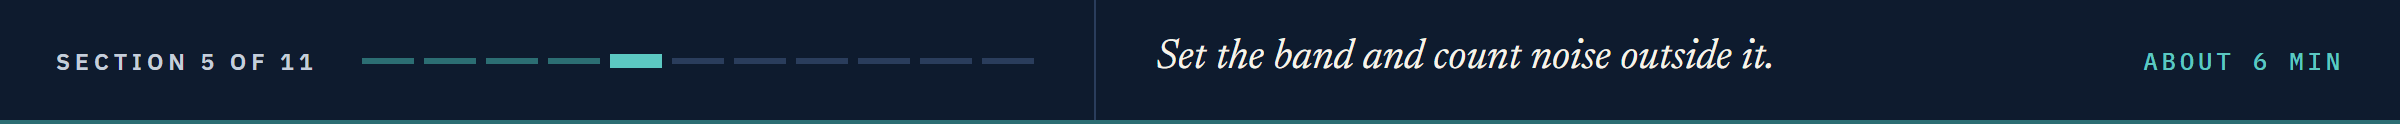

# The Confidence Band

**White noise**, Day 3's term, has a true autocorrelation of 0 at every lag.
A sample of n white noise values still gives bars that are not 0, and about 95 in 100 of them land inside plus or minus 1.96 / sqrt(n).
That range is the **confidence band**: a bar outside it is larger than noise usually makes.

In [10]:
# the band for the 10 Yr's 2,000 changes
band = 1.96 / np.sqrt(len(values))
print("Band: plus or minus", round(band, 4))

Band: plus or minus 0.0438


**Predict 1**

Q. Of the 10 Yr change's 40 bars, lags 1 to 40, how many lie outside the band? Write down a number.

## The ACF of the 10 Yr's Change

`plot_acf(values, lags=40, zero=False, ax=ax)` draws the bars and shades statsmodels' band; `zero=False` leaves out lag 0.

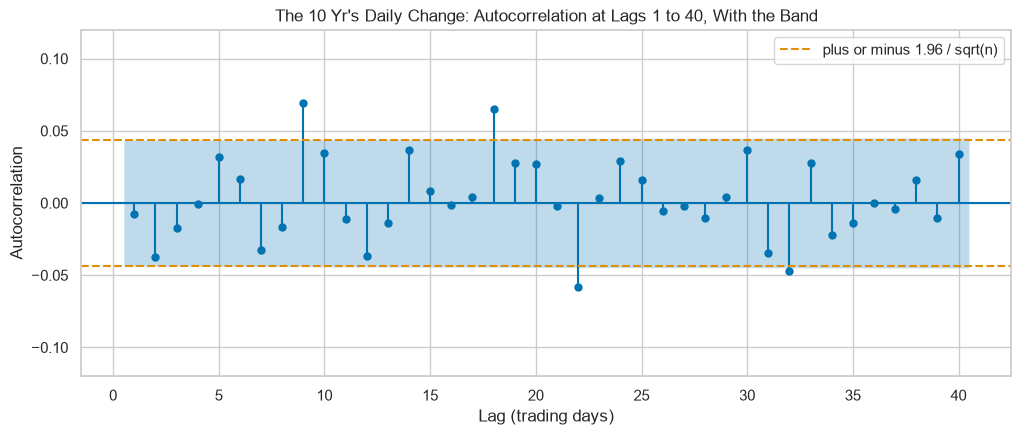

In [11]:
# the 10 Yr change's ACF to lag 40, with our band as dashed lines over statsmodels' shaded one
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_acf(values, lags=40, zero=False, ax=ax)
ax.axhline(band, color="C1", linestyle="--")
ax.axhline(-band, color="C1", linestyle="--", label="plus or minus 1.96 / sqrt(n)")
ax.set(xlabel="Lag (trading days)", ylabel="Autocorrelation", ylim=(-0.12, 0.12))
ax.set_title("The 10 Yr's Daily Change: Autocorrelation at Lags 1 to 40, With the Band")
ax.legend(loc="upper right")
plt.show()

In [12]:
# the 40 bars, and the lags whose bar lies outside the band
bars = acf(values, nlags=40)[1:]
outside = [k for k in range(1, 41) if abs(bars[k - 1]) > band]
print(len(outside), "of 40 outside, at lags", outside)
print("Largest bar:", round(bars[np.abs(bars).argmax()], 4), "at lag", np.abs(bars).argmax() + 1)

4 of 40 outside, at lags [9, 18, 22, 32]
Largest bar: 0.0693 at lag 9


The shaded band widens a little with the lag: statsmodels uses **Bartlett's rule**, which lets each bar's band grow with the bars before it.

Here the two bands mark the same bars.

About 5 in 100 is 2 of 40, so the count above is about twice what noise gives on average.

## What Noise Alone Puts Outside

Q. Is that count unusual for white noise?

In [13]:
# 1,000 white noise series as long as the changes, from one seeded generator: bars outside the band in each
rng = np.random.default_rng(SEED)
noise_counts = []
for i in range(1000):
    noise_bars = acf(rng.standard_normal(len(values)), nlags=40)[1:]
    noise_counts.append(int((np.abs(noise_bars) > band).sum()))
noise_counts = pd.Series(noise_counts)
print("Average outside:", noise_counts.mean(), "| at least one:", (noise_counts >= 1).mean() * 100,
      "percent | as many as the 10 Yr or more:", (noise_counts >= len(outside)).mean() * 100, "percent")

Average outside: 1.923 | at least one: 84.8 percent | as many as the 10 Yr or more: 12.8 percent


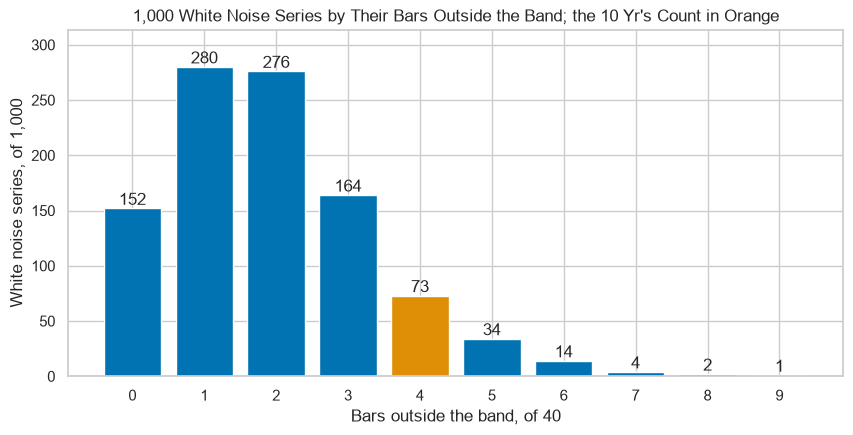

In [14]:
# the 1,000 noise series by how many of their 40 bars lie outside, the 10 Yr's count highlighted
by_count = noise_counts.value_counts().sort_index()
colours = ["C1" if k == len(outside) else "C0" for k in by_count.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
shown = ax.bar(by_count.index, by_count.values, color=colours)
ax.bar_label(shown)
ax.set(xticks=by_count.index, ylim=(0, by_count.max() * 1.12), xlabel="Bars outside the band, of 40", ylabel="White noise series, of 1,000")
ax.set_title("1,000 White Noise Series by Their Bars Outside the Band; the 10 Yr's Count in Orange")
plt.show()

Noise puts about two bars of 40 outside, and most noise series have at least one.

About one noise series in eight has at least as many bars outside as the 10 Yr's change.

## Your Turn: Find the Real One

Twenty ACFs follow: nineteen of white noise as long as the changes, and the 10 Yr's change at a place the generator picks.
Write down which panel you think is real before you run the cell after the chart.

In [15]:
# one ACF as bars: the band shaded, bars outside it in orange
def draw_acf(ax, bars, band):
    colours = ["C1" if abs(b) > band else "C0" for b in bars]
    ax.bar(range(1, len(bars) + 1), bars, color=colours, width=0.7)
    ax.axhspan(-band, band, color="C0", alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.8)

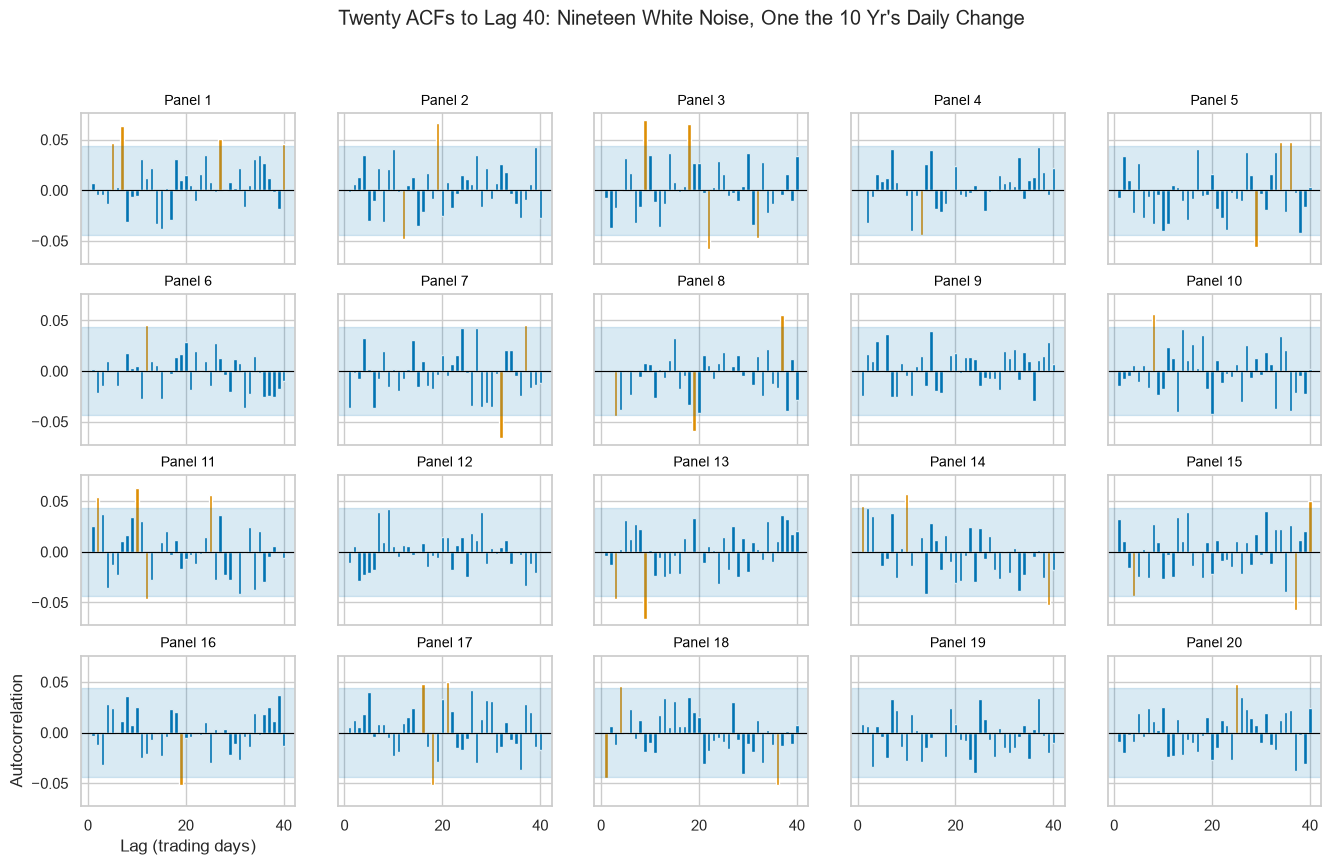

In [16]:
# twenty panels: nineteen noise ACFs and the 10 Yr's at a place drawn by the generator
real = int(rng.integers(20))
lineup = [acf(rng.standard_normal(len(values)), nlags=40)[1:] for i in range(20)]
lineup[real] = bars

# draw the twenty, numbered 1 to 20; ring= outlines one panel
def draw_lineup(ring=None):
    fig, axes = plt.subplots(4, 5, figsize=(16, 9), sharex=True, sharey=True)
    for k, ax in enumerate(axes.flat):
        draw_acf(ax, lineup[k], band)
        ax.set_title(f"Panel {k + 1}", fontsize=10, color="C1" if k == ring else "black")
        if k == ring:
            # ax.patch is the panel's background rectangle: an orange edge on it draws the ring
            ax.patch.set(edgecolor="C1", linewidth=4)
    axes[3, 0].set(xlabel="Lag (trading days)", ylabel="Autocorrelation")
    fig.suptitle("Twenty ACFs to Lag 40: Nineteen White Noise, One the 10 Yr's Daily Change", y=0.995)
    plt.show()

draw_lineup()

The 10 Yr is panel 3
Bars outside, panels 1 to 20: [4, 2, 4, 1, 3, 1, 2, 3, 0, 1, 4, 0, 2, 3, 3, 1, 3, 3, 0, 1]


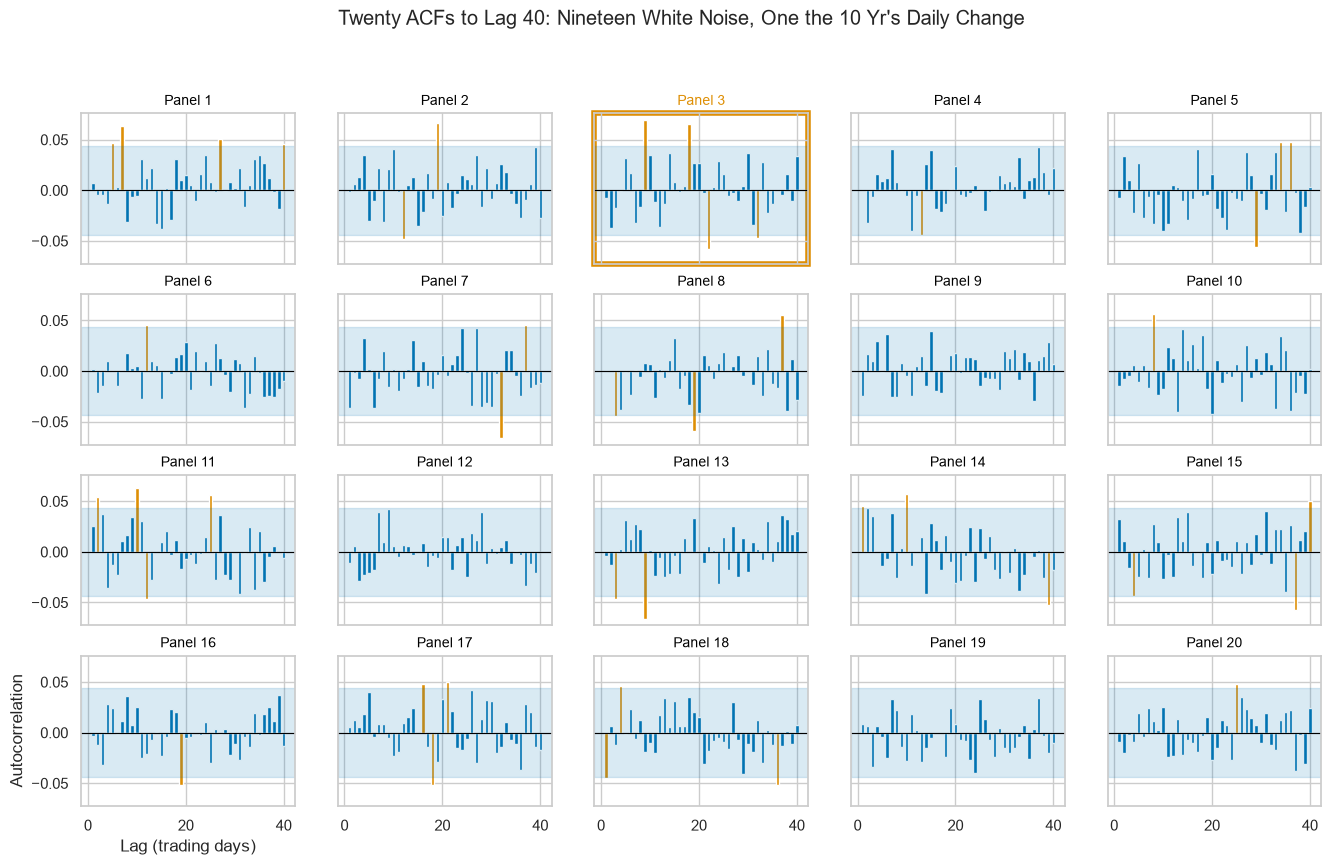

In [17]:
# the answer: which panel is the 10 Yr, and how many bars lie outside in each panel
print("The 10 Yr is panel", real + 1)
print("Bars outside, panels 1 to 20:", [int((np.abs(b) > band).sum()) for b in lineup])
draw_lineup(ring=real)

Panels 1 and 11 are noise and carry four bars outside, as many as the 10 Yr's change.

Without the ring, the real one is a face in the crowd.

**A bar outside the band is a reason to look, not proof of memory: noise puts one in twenty outside.**

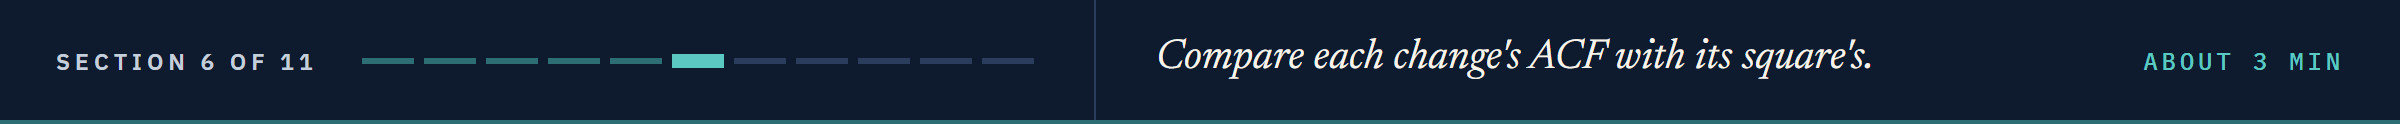

# Changes and Squared Changes

A squared change keeps the size of a day's move and throws its sign away.

**Predict 2**

Q. Sketch the ACF of the squared 10 Yr change to lag 40, and write down how many of its 40 bars lie outside the band.

## The ACF of the Squared Change

In [18]:
# the squared change: each day's move in bp, squared
squares = values ** 2
square_bars = acf(squares, nlags=40)[1:]
print("Lags 1, 5, 20, 40:", square_bars[[0, 4, 19, 39]].round(4))
print("Outside the band:", (np.abs(square_bars) > band).sum(), "of 40 | lowest bar:", round(square_bars.min(), 4))
print("Absolute change, outside the band:", (np.abs(acf(np.abs(values), nlags=40)[1:]) > band).sum(), "of 40")

Lags 1, 5, 20, 40: [0.2249 0.2139 0.0849 0.0699]
Outside the band: 34 of 40 | lowest bar: 0.0136
Absolute change, outside the band: 40 of 40


## The Move and Its Size

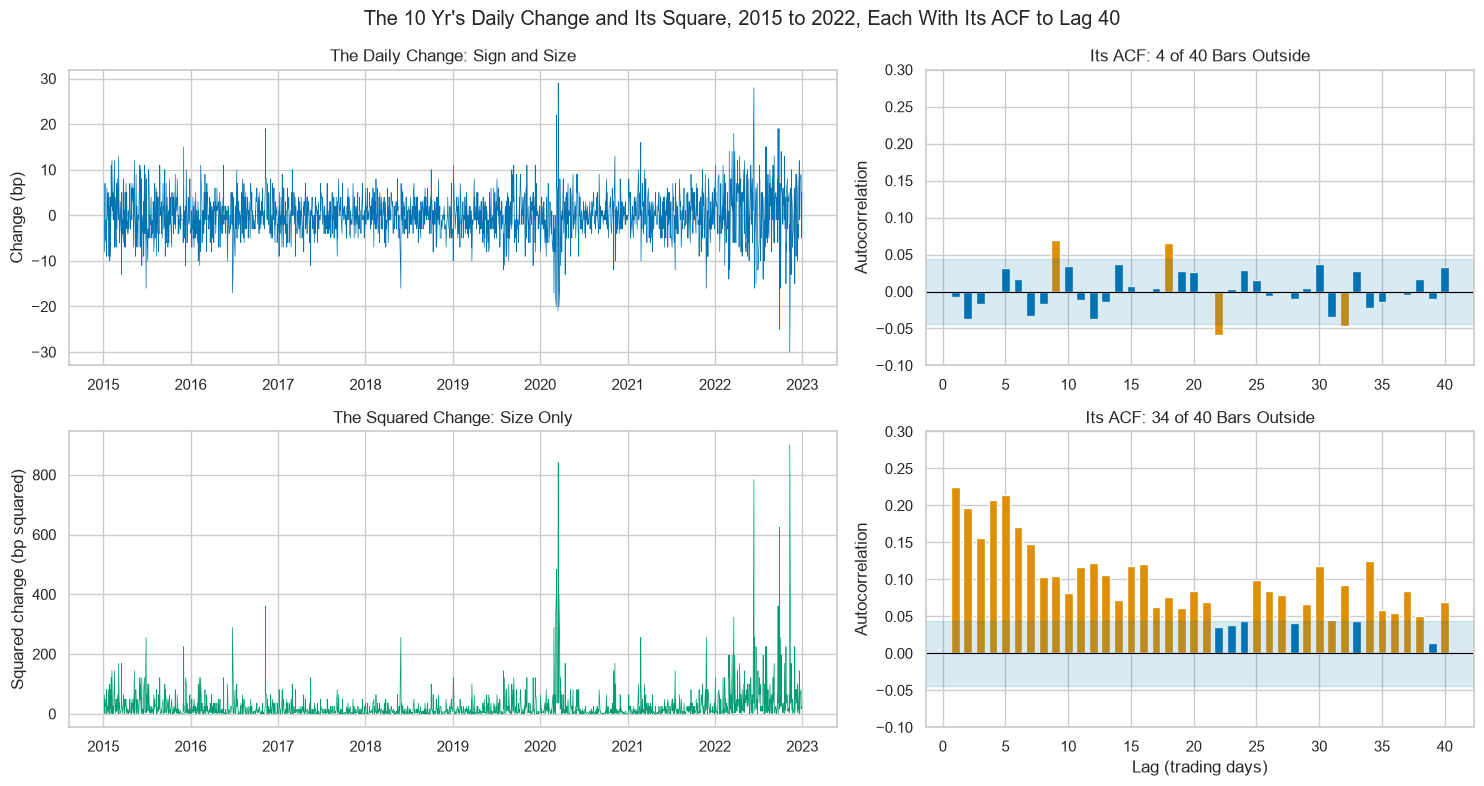

In [19]:
# left: the change and the squared change over the dates; right: each one's ACF against the band
fig, axes = plt.subplots(2, 2, figsize=(15, 8), width_ratios=[1.4, 1])
axes[0, 0].plot(ten.index, values, linewidth=0.5)
axes[1, 0].plot(ten.index, squares, linewidth=0.5, color="C2")
draw_acf(axes[0, 1], bars, band)
draw_acf(axes[1, 1], square_bars, band)
axes[0, 0].set(ylabel="Change (bp)", title="The Daily Change: Sign and Size")
axes[1, 0].set(ylabel="Squared change (bp squared)", title="The Squared Change: Size Only")
axes[0, 1].set(ylim=(-0.1, 0.3), ylabel="Autocorrelation", title=f"Its ACF: {len(outside)} of 40 Bars Outside")
axes[1, 1].set(ylim=(-0.1, 0.3), ylabel="Autocorrelation", xlabel="Lag (trading days)", title=f"Its ACF: {(np.abs(square_bars) > band).sum()} of 40 Bars Outside")
fig.suptitle("The 10 Yr's Daily Change and Its Square, 2015 to 2022, Each With Its ACF to Lag 40")
plt.tight_layout()
plt.show()

The bars of the change sit around zero, a few outside the band; the squares' bars sit far above it, falling slowly.

The squares are tall where Day 2's calendar heatmap was dark: March 2020 and through 2022.

A big day follows big days, whichever way each one moved.

## Every Series

Q. Does the same hold for the other four series?

In [20]:
# for each series: the lag-1 autocorrelation and the bars outside the band, for the change and its square
rows = []
for name in changes.columns:
    change_bars = acf(changes[name].to_numpy(), nlags=40)[1:]
    size_bars = acf(changes[name].to_numpy() ** 2, nlags=40)[1:]
    rows.append({"series": name, "change, lag 1": change_bars[0], "change, outside": int((np.abs(change_bars) > band).sum()),
                 "square, lag 1": size_bars[0], "square, outside": int((np.abs(size_bars) > band).sum())})
memory = pd.DataFrame(rows).set_index("series")
memory

,"change, lag 1","change, outside","square, lag 1","square, outside"
series,,,,
2 Yr,-0.0248,10,0.1792,40
10 Yr,-0.0075,4,0.2249,34
2s10s,-0.0219,4,0.1438,36
IG,-0.0486,8,0.1556,30
HY,0.0095,6,0.1512,36


The changes put 4 to 10 bars of 40 outside; the 2 Yr the most.

The squares put 30 or more outside on every series.

**The sign of a day's move remembers little and its size remembers a lot. Day 5 models the first, Day 7 the second.**

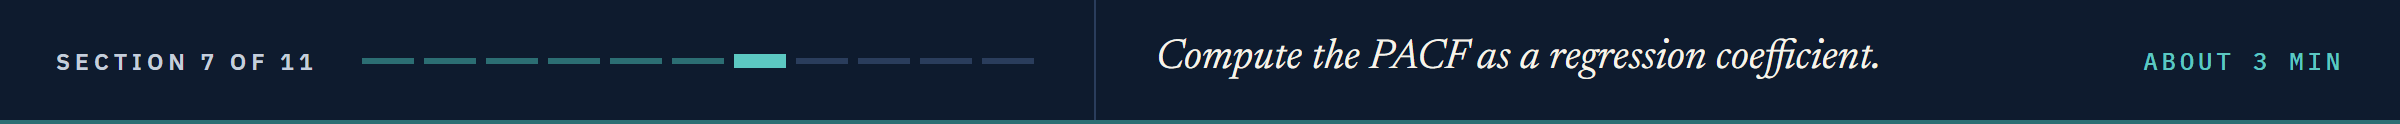

# The Partial Autocorrelation

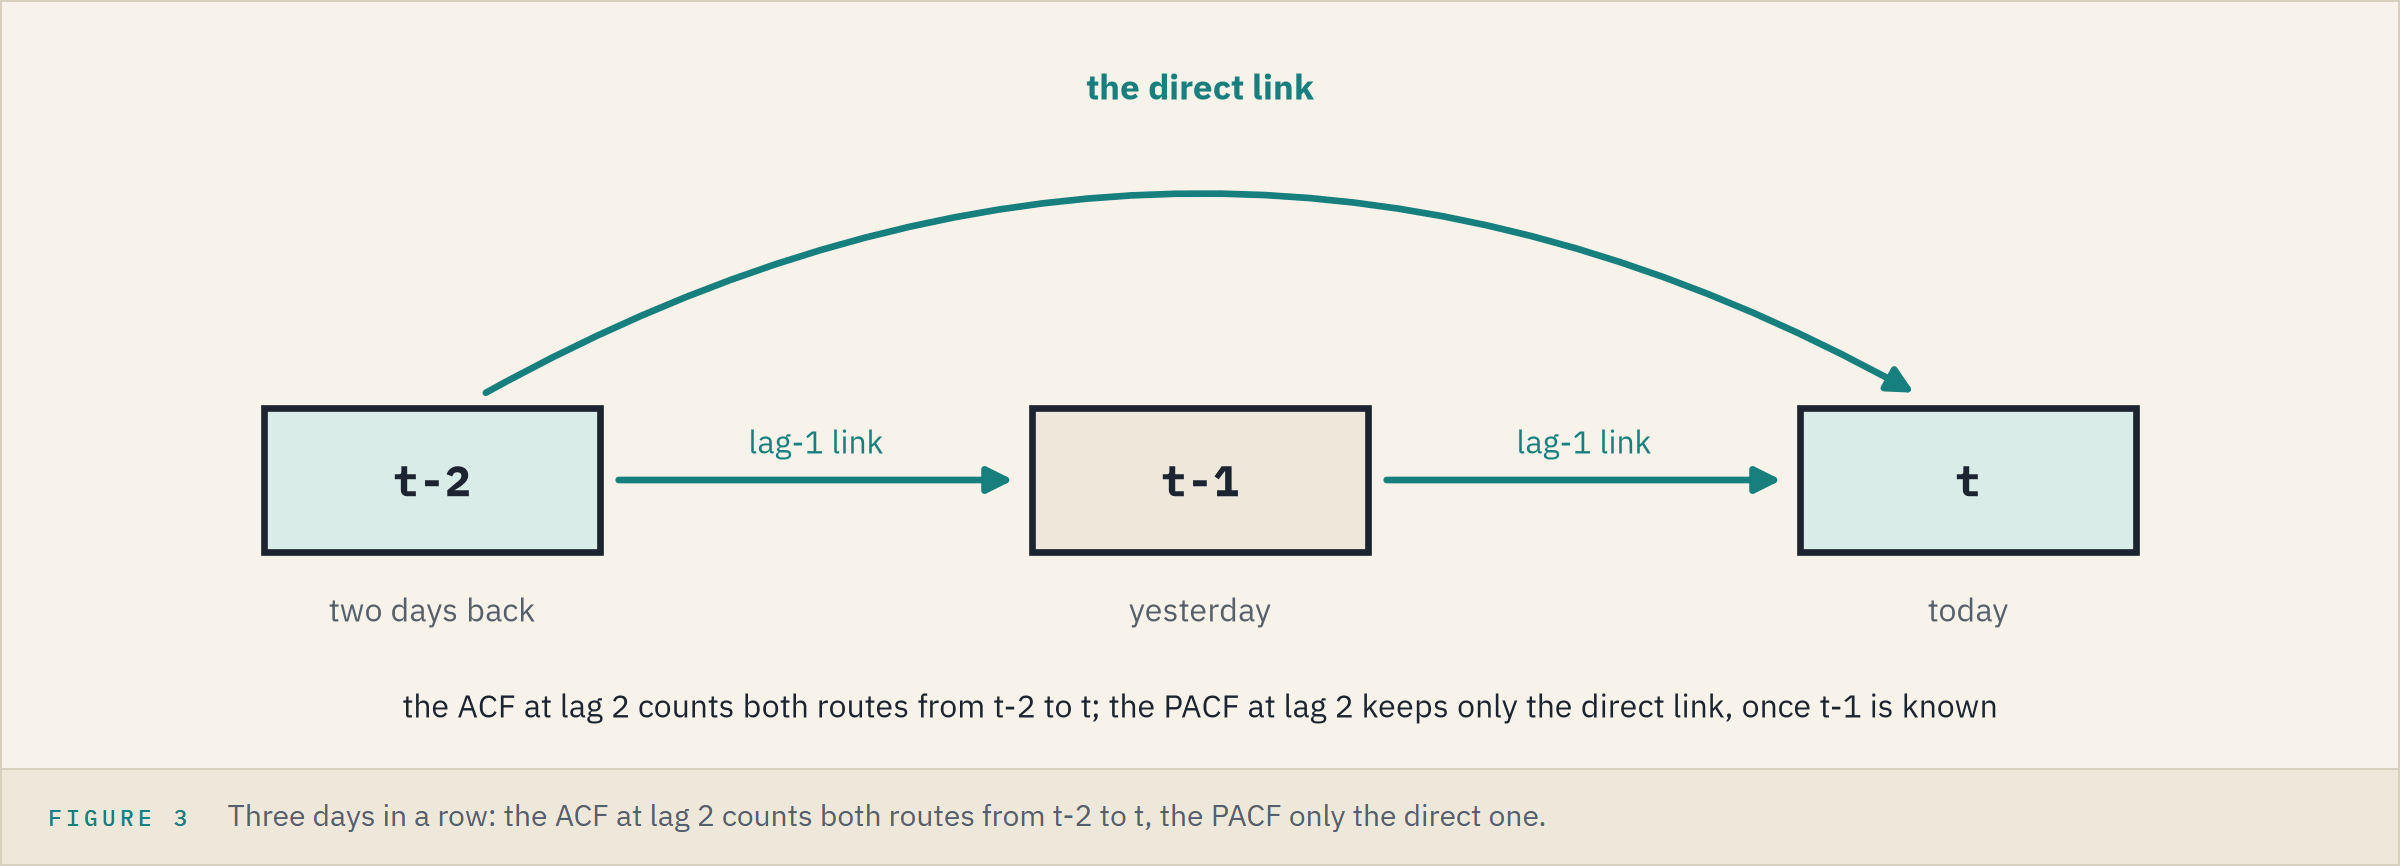

A value two days back can reach today two ways: straight, or through yesterday.
The ACF at lag 2 counts both routes.
The **partial autocorrelation** at lag k keeps only the direct one: the link between today and k days back once the days between are known.
The **PACF** is that number at every lag, and `pacf(values, nlags=k)` returns it.

## The PACF as a Regression

Q. What is the partial autocorrelation at lag 2, written as a regression?

In [21]:
# the change against its own lag-1 and lag-2 columns, fitted with Course 4's OLS
rows_2 = pd.DataFrame({"change": ten, "lag 1": ten.shift(1), "lag 2": ten.shift(2)}).dropna()
ols = sm.OLS(rows_2["change"], sm.add_constant(rows_2[["lag 1", "lag 2"]])).fit()
print("Lag-2 coefficient of the regression:", ols.params["lag 2"])
print("pacf at lag 2, OLS method:          ", pacf(values, nlags=2, method="ols")[2])
print("pacf at lag 2, its default method:  ", pacf(values, nlags=2)[2])

Lag-2 coefficient of the regression: -0.03734831394052713
pacf at lag 2, OLS method:           -0.037348313940527136
pacf at lag 2, its default method:   -0.03734460942214217


The PACF at lag k is the last coefficient of a regression on the k lags before.

`method="ols"` runs exactly that regression; the default reaches the number from the ACF instead of a regression, and differs in the sixth decimal.

## The PACF of the Change and of Its Square

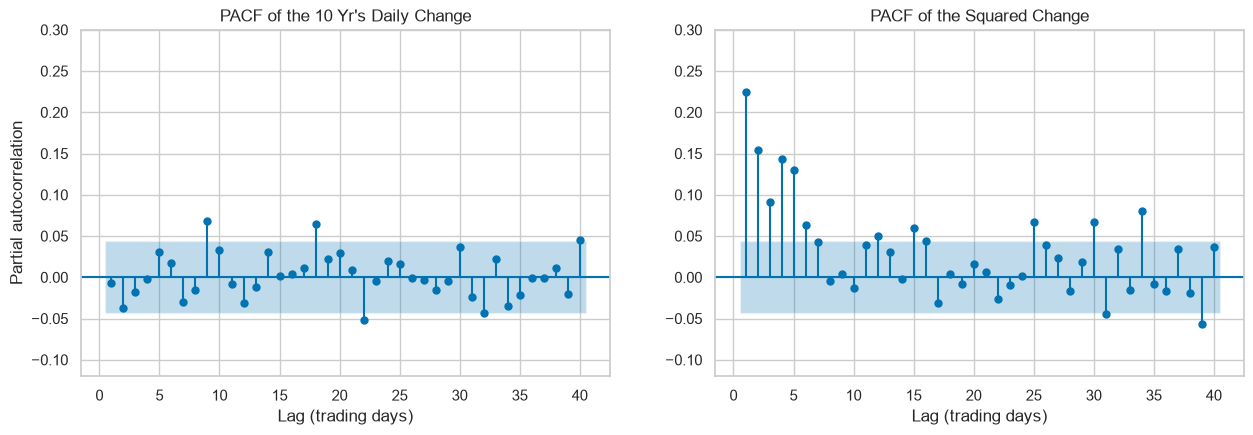

In [22]:
# the PACF to lag 40 of the change and of its square, side by side
# plot_pacf's own default method differs a little from pacf's, so we pass pacf's, "ywadjusted": chart and count agree
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
plot_pacf(values, lags=40, zero=False, method="ywadjusted", ax=axes[0])
plot_pacf(squares, lags=40, zero=False, method="ywadjusted", ax=axes[1])
axes[0].set(xlabel="Lag (trading days)", ylabel="Partial autocorrelation", ylim=(-0.12, 0.3),
            title="PACF of the 10 Yr's Daily Change")
axes[1].set(xlabel="Lag (trading days)", ylim=(-0.12, 0.3), title="PACF of the Squared Change")
plt.show()

In [23]:
# the lags outside the band, for each PACF
change_partial = pacf(values, nlags=40)[1:]
square_partial = pacf(squares, nlags=40)[1:]
print("Change, outside:", [k for k in range(1, 41) if abs(change_partial[k - 1]) > band])
print("Square, outside:", [k for k in range(1, 41) if abs(square_partial[k - 1]) > band])
print("Square, lags 1 to 6:", square_partial[:6].round(3))

Change, outside: [9, 18, 22, 32, 40]
Square, outside: [1, 2, 3, 4, 5, 6, 12, 15, 25, 30, 31, 34, 39]
Square, lags 1 to 6: [0.225 0.154 0.091 0.144 0.13  0.064]


The change's PACF looks like its ACF: a few scattered bars outside.

The square's PACF lies outside at each of the first six lags, then only at scattered ones: much of the ACF's long tail is those first lags passed along.

**The ACF shows all the memory; the PACF shows how many lags carry it directly. Together they name a model.**

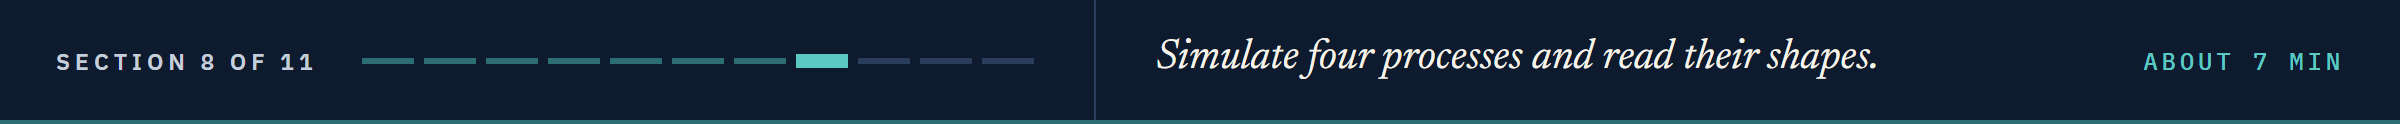

# The Identification Grid

Day 3's AR(1) said: value = phi times the last value plus a shock.
An **AR(p)** model extends it to the last p values, each with its own coefficient.
An **MA(q)** model makes the value a shock plus a part, **theta**, of each of the last q shocks.
An **ARMA(p, q)** has both.
`ArmaProcess(ar=..., ma=...)` builds one from two lists: the AR list is 1, then minus each phi; the MA list is 1, then each theta.
Its `.generate_sample(nsample=, distrvs=rng.standard_normal, burnin=)` draws the shocks from our generator and drops the first `burnin` values, and `.acf()` and `.pacf()` give the exact values the process makes.

**Predict 3**

Q. An AR(1) with phi 0.7 has an autocorrelation of 0.7 at lag 1. Write down its autocorrelation at lag 3.

## An AR(1) With Phi 0.7

In [24]:
# an AR(1) with phi 0.7: the AR list is 1, then minus 0.7; no MA terms, so the MA list is just 1
ar1 = ArmaProcess(ar=[1, -0.7], ma=[1])
ar1_values = ar1.generate_sample(nsample=2000, distrvs=rng.standard_normal, burnin=100)
print("Exact ACF, lags 1 to 5: ", ar1.acf(lags=6)[1:].round(3))
print("Sample ACF, lags 1 to 5:", acf(ar1_values, nlags=5)[1:].round(3))
print("Exact PACF, lags 1 and 2: ", ar1.pacf(lags=3)[1:].round(3))
print("Sample PACF, lags 1 and 2:", pacf(ar1_values, nlags=2)[1:].round(3))

Exact ACF, lags 1 to 5:  [0.7   0.49  0.343 0.24  0.168]
Sample ACF, lags 1 to 5: [0.708 0.479 0.323 0.221 0.15 ]
Exact PACF, lags 1 and 2:  [0.7 0. ]
Sample PACF, lags 1 and 2: [ 0.708 -0.045]


The exact ACF is 0.7, then 0.7 times 0.7, then 0.7 times that: each lag multiplies by phi.

The sample of 2,000 values comes within a few hundredths of it.

The exact PACF is 0 at lag 2: in an AR(1) the day before carries all the memory.

The sample's lag 2 lands just outside the band: the kind of bar noise puts outside one time in twenty.

## Four Processes Side by Side

In [25]:
# four processes the grid compares, each drawn 2,000 values long from the same generator
processes = {"AR(1), phi 0.7": ArmaProcess(ar=[1, -0.7], ma=[1]),
             "AR(2), phi 0.5, -0.3": ArmaProcess(ar=[1, -0.5, 0.3], ma=[1]),
             "MA(1), theta 0.8": ArmaProcess(ar=[1], ma=[1, 0.8]),
             "ARMA(1, 1), 0.7, 0.5": ArmaProcess(ar=[1, -0.7], ma=[1, 0.5])}
samples = {name: process.generate_sample(nsample=2000, distrvs=rng.standard_normal, burnin=100)
           for name, process in processes.items()}

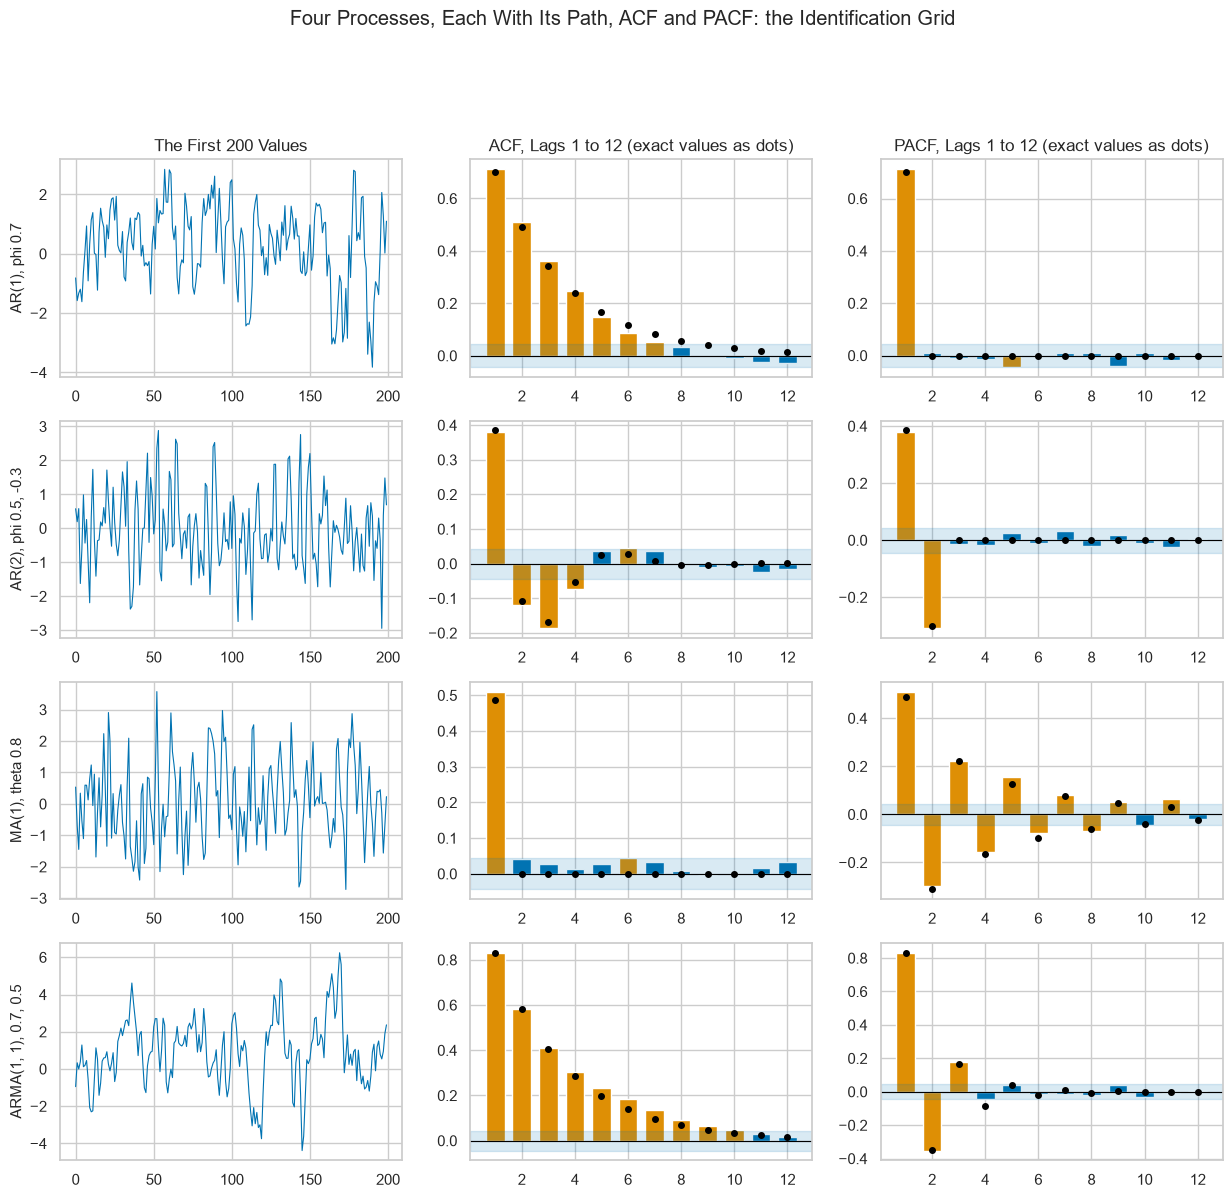

In [26]:
# rows: the four processes; columns: the first 200 values, the ACF and the PACF to lag 12, exact values as dots
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for row, (name, process) in enumerate(processes.items()):
    axes[row, 0].plot(samples[name][:200], linewidth=0.8)
    draw_acf(axes[row, 1], acf(samples[name], nlags=12)[1:], band)
    axes[row, 1].plot(range(1, 13), process.acf(lags=13)[1:], "o", color="black", markersize=4)
    draw_acf(axes[row, 2], pacf(samples[name], nlags=12)[1:], band)
    axes[row, 2].plot(range(1, 13), process.pacf(lags=13)[1:], "o", color="black", markersize=4)
    axes[row, 0].set_ylabel(name, fontsize=11)
axes[0, 0].set_title("The First 200 Values")
axes[0, 1].set_title("ACF, Lags 1 to 12 (exact values as dots)")
axes[0, 2].set_title("PACF, Lags 1 to 12 (exact values as dots)")
fig.suptitle("Four Processes, Each With Its Path, ACF and PACF: the Identification Grid", y=0.995)
plt.show()

In [27]:
# the lags outside the band in each sample's ACF and PACF, lags 1 to 12
for name, sample in samples.items():
    print(name, "| ACF outside:", [k for k in range(1, 13) if abs(acf(sample, nlags=12)[k]) > band],
          "| PACF outside:", [k for k in range(1, 13) if abs(pacf(sample, nlags=12)[k]) > band])

AR(1), phi 0.7 | ACF outside: [1, 2, 3, 4, 5, 6, 7] | PACF outside: [1, 5]
AR(2), phi 0.5, -0.3 | ACF outside: [1, 2, 3, 4, 6] | PACF outside: [1, 2]
MA(1), theta 0.8 | ACF outside: [1, 6] | PACF outside: [1, 2, 3, 4, 5, 6, 7, 8, 9, 11]
ARMA(1, 1), 0.7, 0.5 | ACF outside: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | PACF outside: [1, 2, 3]


### Interpretation of the Grid

An AR(p): the ACF decays slowly, and the PACF **cuts off** after lag p, falling to the band at once.

An MA(q): the ACF cuts off after lag q, and the PACF decays.

An ARMA(p, q): both decay.

A stray bar, such as the AR(1)'s PACF at lag 5 or the MA(1)'s ACF at lag 6, is the one in twenty noise puts outside.

## Your Turn: Move Phi and Theta

In [28]:
# the path, ACF and PACF of an ARMA(1, 1) on one row of three axes, from a fresh generator each time
def arma_row(axes, phi, theta):
    sample = ArmaProcess(ar=[1, -phi], ma=[1, theta]).generate_sample(
        nsample=2000, distrvs=np.random.default_rng(SEED).standard_normal, burnin=100)
    axes[0].plot(sample[:200], linewidth=0.8)
    draw_acf(axes[1], acf(sample, nlags=12)[1:], band)
    draw_acf(axes[2], pacf(sample, nlags=12)[1:], band)
    axes[0].set_ylabel(f"phi {phi:.1f}, theta {theta:.1f}")

In [29]:
# your turn: move phi and theta and watch the ACF and the PACF change shape
def draw_arma(phi=0.7, theta=0.0):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    arma_row(axes, phi, theta)
    axes[1].set_title("ACF, Lags 1 to 12")
    axes[2].set_title("PACF, Lags 1 to 12")
    plt.show()

interact(draw_arma, phi=(-0.9, 0.9, 0.1), theta=(-0.9, 0.9, 0.1));

interactive(children=(FloatSlider(value=0.7, description='phi', max=0.9, min=-0.9), FloatSlider(value=0.0, des…

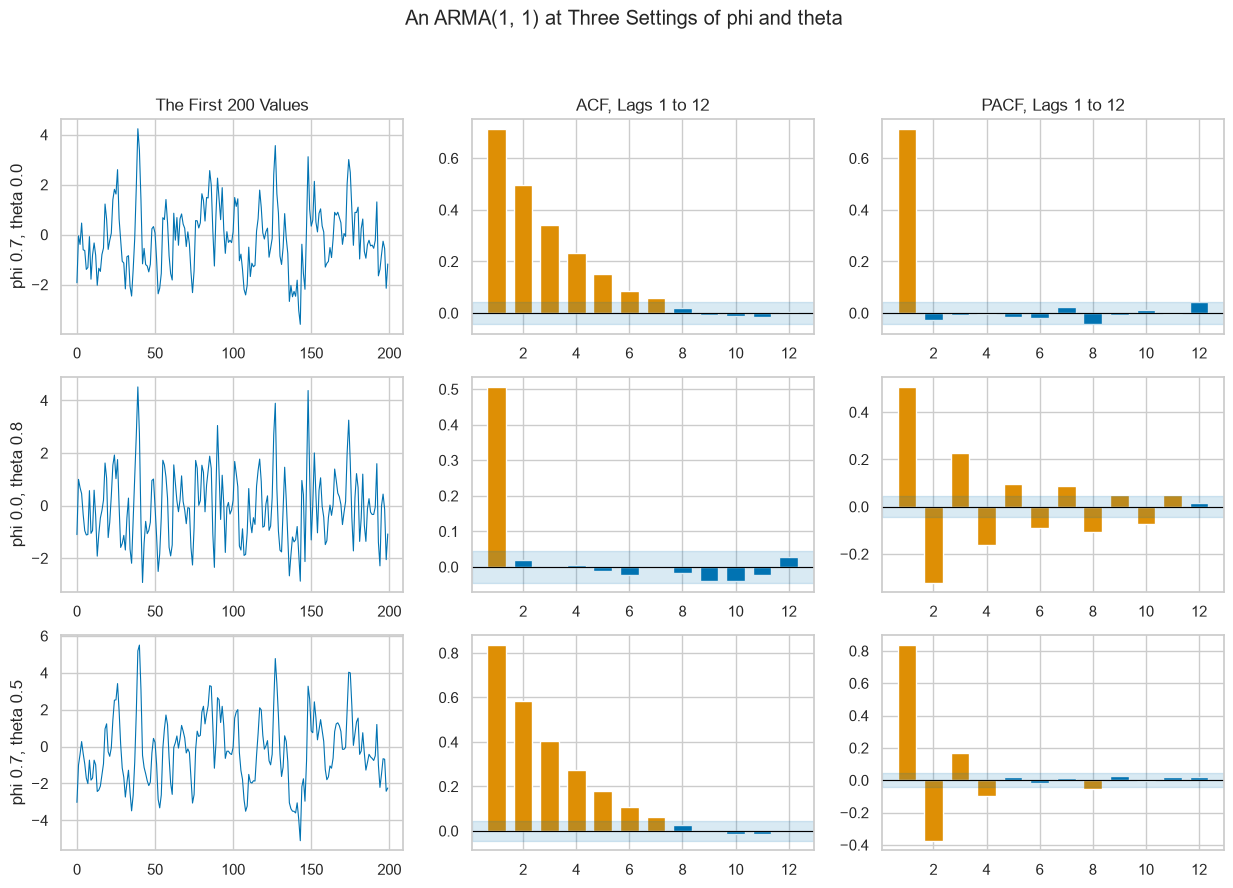

In [30]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
# with two more settings below it: theta alone, then both
fig, axes = plt.subplots(3, 3, figsize=(15, 9.5))
for row, (phi, theta) in enumerate([(0.7, 0.0), (0.0, 0.8), (0.7, 0.5)]):
    arma_row(axes[row], phi, theta)
axes[0, 0].set_title("The First 200 Values")
axes[0, 1].set_title("ACF, Lags 1 to 12")
axes[0, 2].set_title("PACF, Lags 1 to 12")
fig.suptitle("An ARMA(1, 1) at Three Settings of phi and theta", y=0.995)
plt.show()

## Reading a Series You Made on Day 3

Day 3 differenced the 10 Yr twice and found a lag-1 autocorrelation near minus a half.
Read its pictures with the grid.

In [31]:
# the 10 Yr's second difference: the change in the daily change
second = np.diff(values)
second_bars = acf(second, nlags=12)[1:]
second_partial = pacf(second, nlags=12)[1:]
print("ACF, lags 1 to 5: ", second_bars[:5].round(3))
print("PACF, lags 1 to 5:", second_partial[:5].round(3))
print("PACF outside the band:", (np.abs(second_partial) > band).sum(), "of 12")

ACF, lags 1 to 5:  [-0.485 -0.025  0.002 -0.009  0.024]
PACF, lags 1 to 5: [-0.485 -0.34  -0.265 -0.236 -0.181]
PACF outside the band: 12 of 12


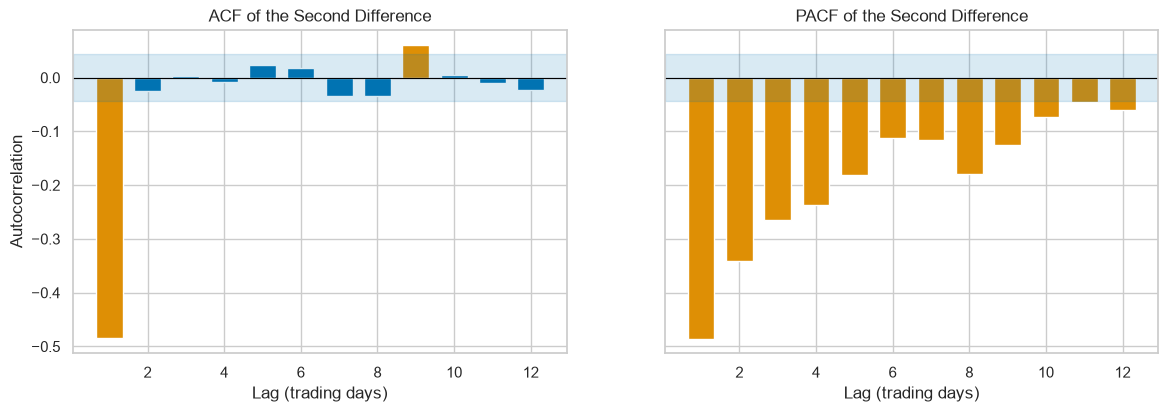

In [32]:
# its ACF and PACF to lag 12, side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
draw_acf(axes[0], second_bars, band)
draw_acf(axes[1], second_partial, band)
axes[0].set(xlabel="Lag (trading days)", ylabel="Autocorrelation", title="ACF of the Second Difference")
axes[1].set(xlabel="Lag (trading days)", title="PACF of the Second Difference")
plt.show()

The ACF has one large bar, at lag 1, and the PACF decays over many lags: the grid's MA(1).

Differencing once too often makes an MA(1) out of a series that had none.

**On the real changes neither picture cuts off cleanly, so we need a test that weighs many bars together.**

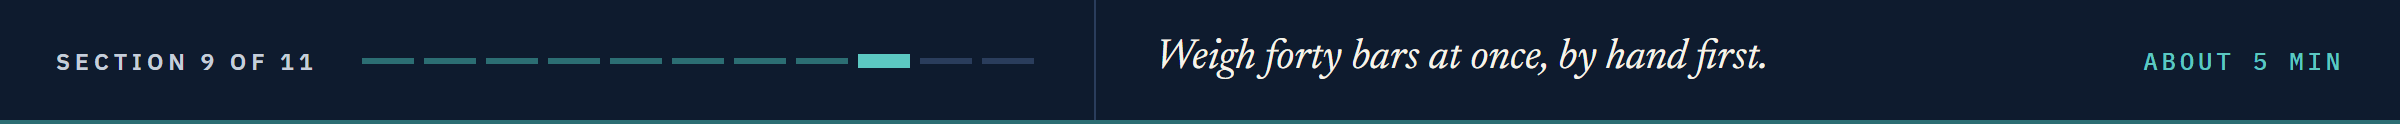

# The Ljung-Box Test

The **Ljung-Box test** asks whether the first m bars, taken together, are larger than white noise makes.
Its null hypothesis: no autocorrelation at any lag up to m.
Its **Q statistic** is n (n + 2) times the sum, over lags k from 1 to m, of the squared bar divided by n - k.
Under the null, Q comes close to the **chi-squared distribution** with m **degrees of freedom**, and `stats.chi2.ppf(0.95, m)` gives the value Q must pass to reject at 5 percent.

## Q by Hand

In [33]:
# Q for the 10 Yr's change at 10 lags, by hand
n = len(values)
lags_10 = np.arange(1, 11)
q_by_hand = n * (n + 2) * np.sum(bars[:10] ** 2 / (n - lags_10))
print("Q by hand:", round(q_by_hand, 4), "| to reject at 5 percent, Q must pass", round(stats.chi2.ppf(0.95, 10), 2))

Q by hand: 20.8096 | to reject at 5 percent, Q must pass 18.31


In [34]:
# the same test from statsmodels: Q in lb_stat and its p-value in lb_pvalue, one row per lag asked for
acorr_ljungbox(values, lags=[10])

,lb_stat,lb_pvalue
10,20.8096,0.0225


The two Q values agree, and Q passes its critical value: the test rejects the null of no autocorrelation for the 10 Yr's change at 10 lags.

**Predict 4**

Q. At 10 lags, for how many of the five series' changes does Ljung-Box reject at 5 percent? Write down a number.

## Five Series, Changes and Squares

In [35]:
# the p-values at 10 and 20 lags for each series' change and its square
rows = []
for name in changes.columns:
    for kind, series in [("change", changes[name]), ("square", changes[name] ** 2)]:
        test = acorr_ljungbox(series.to_numpy(), lags=[10, 20])
        rows.append({"series": name, "kind": kind, "p, 10 lags": test["lb_pvalue"].iloc[0],
                     "p, 20 lags": test["lb_pvalue"].iloc[1]})
ljung = pd.DataFrame(rows).set_index(["series", "kind"])

# .xs("square", level="kind") keeps the rows labelled square; e-notation shows how small their p-values are
print("Largest p-value of a square:", f"{ljung.xs('square', level='kind').max().max():.1e}")
ljung

Largest p-value of a square: 1.7e-60


p, 10 lags  p, 20 lags
series kind                          
2 Yr   change      0.0051      0.0000
       square      0.0000      0.0000
10 Yr  change      0.0225      0.0074
       square      0.0000      0.0000
2s10s  change      0.1461      0.0252
       square      0.0000      0.0000
IG     change      0.0024      0.0005
       square      0.0000      0.0000
HY     change      0.6674      0.5495
       square      0.0000      0.0000

At 10 lags the test rejects for the 2 Yr, the 10 Yr and IG; at 20 lags for all but HY.

Every square's p-value is below 1e-59, so the table shows 0.0000: on all five series the size of a move is not white noise.

## Q Lag by Lag

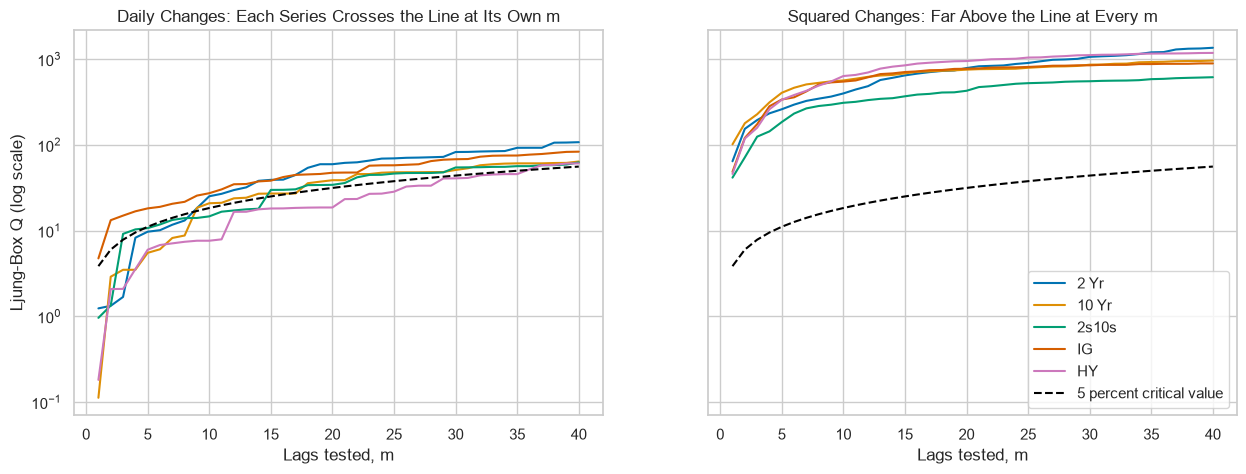

In [36]:
# Q at every lag from 1 to 40, each series' change and square, against the 5 percent critical value
lags_40 = np.arange(1, 41)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for name in changes.columns:
    axes[0].plot(lags_40, acorr_ljungbox(changes[name].to_numpy(), lags=40)["lb_stat"], label=name)
    axes[1].plot(lags_40, acorr_ljungbox(changes[name].to_numpy() ** 2, lags=40)["lb_stat"], label=name)
for ax in axes:
    ax.plot(lags_40, stats.chi2.ppf(0.95, lags_40), color="black", linestyle="--", label="5 percent critical value")
    ax.set(yscale="log", xlabel="Lags tested, m")
axes[0].set(ylabel="Ljung-Box Q (log scale)", title="Daily Changes: Each Series Crosses the Line at Its Own m")
axes[1].set(title="Squared Changes: Far Above the Line at Every m")
axes[1].legend(loc="lower right")
plt.show()

In [37]:
# the first m at which each series' change rejects at 5 percent
for name in changes.columns:
    p_values = acorr_ljungbox(changes[name].to_numpy(), lags=40)["lb_pvalue"]
    print(name, "first rejects at m =", p_values[p_values < 0.05].index.min())

2 Yr first rejects at m = 9
10 Yr first rejects at m = 9
2s10s first rejects at m = 3
IG first rejects at m = 1
HY first rejects at m = 36


The 10 Yr's Q crosses its critical value at 9 lags, as does the 2 Yr's; IG's from the first lag; HY's only near the end.

The 2s10s rejects at 3 lags, not at 10, and again from 15, so the verdict depends on m: choose m before reading the answer.

The squares sit far above the dashed line at every m.

### Interpretation of the 10 Yr's Q

In [38]:
# each lag's share of the 10 Yr's Q at 10 lags, and Q without lag 9
terms = n * (n + 2) * bars[:10] ** 2 / (n - lags_10)
print("Lag 9's share of Q:", round(terms[8] / terms.sum() * 100, 1), "percent")
print("Q without lag 9:", round(terms.sum() - terms[8], 2), "against", round(stats.chi2.ppf(0.95, 10), 2))

Lag 9's share of Q: 46.5 percent
Q without lag 9: 11.14 against 18.31


Nearly half of the 10 Yr's Q is one lag, lag 9.

Without it Q would sit under the critical value.

**The 10 Yr's test leans on one lag. Before a model leans on it too, see whether it holds across the years.**

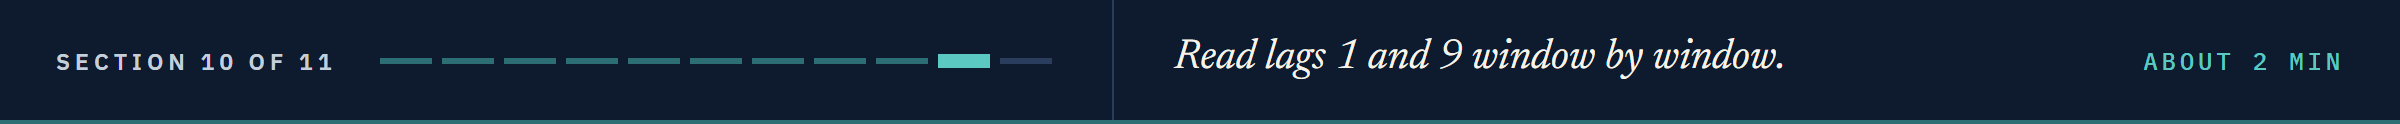

# Checking a Bar Across the Years

## The Band Widens on Fewer Dates

The band is 1.96 / sqrt(n), so a shorter window has a wider band.
We read lags 1 and 9 on Day 2's five test windows of 252 dates and on the two halves of the development years.

In [39]:
# Day 2's five folds: only their test windows are used here
folds = TimeSeriesSplit(n_splits=5, test_size=252)
windows = {f"fold {k}": changes.index[test] for k, (train, test) in enumerate(folds.split(changes), start=1)}

# the two halves of the development years, and the whole of them
windows["first half"] = changes.index[:1000]
windows["second half"] = changes.index[1000:]
windows["all"] = changes.index

In [40]:
# for each window: its dates, its band, and the 10 Yr's autocorrelation at lags 1 and 9
spans = pd.DataFrame({"dates": [len(d) for d in windows.values()],
                      "first": [d[0].date() for d in windows.values()],
                      "band": [1.96 / np.sqrt(len(d)) for d in windows.values()],
                      "lag 1": [acf(ten.loc[d].to_numpy(), nlags=9)[1] for d in windows.values()],
                      "lag 9": [acf(ten.loc[d].to_numpy(), nlags=9)[9] for d in windows.values()]},
                     index=windows.keys())
spans

,dates,first,band,lag 1,lag 9
fold 1,252,2017-12-15,0.1235,-0.0268,-0.0404
fold 2,252,2018-12-20,0.1235,-0.0749,0.0556
fold 3,252,2019-12-24,0.1235,0.0777,0.0848
fold 4,252,2020-12-28,0.1235,-0.0666,0.1512
fold 5,252,2021-12-29,0.1235,0.0275,0.1064
first half,1000,2015-01-05,0.0620,-0.0556,-0.0030
second half,1000,2019-01-03,0.0620,0.0190,0.1084
all,2000,2015-01-05,0.0438,-0.0075,0.0693


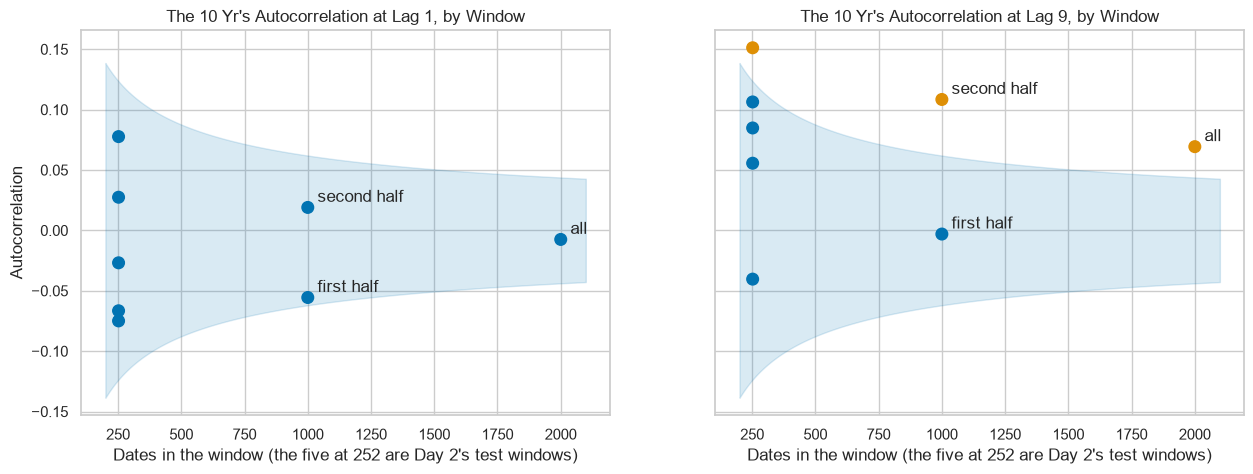

In [41]:
# a funnel: each window's autocorrelation against its dates, the band's two curves shaded, orange outside them
sizes = np.arange(200, 2100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, lag in zip(axes, ["lag 1", "lag 9"]):
    ax.fill_between(sizes, -1.96 / np.sqrt(sizes), 1.96 / np.sqrt(sizes), color="C0", alpha=0.15)
    colours = ["C1" if abs(a) > b else "C0" for a, b in zip(spans[lag], spans["band"])]
    ax.scatter(spans["dates"], spans[lag], s=70, color=colours, zorder=3)
    for name in ["first half", "second half", "all"]:
        ax.annotate(name, (spans.loc[name, "dates"], spans.loc[name, lag]), xytext=(7, 4), textcoords="offset points")
    ax.set(xlabel="Dates in the window (the five at 252 are Day 2's test windows)",
           title=f"The 10 Yr's Autocorrelation at {lag.title()}, by Window")
axes[0].set_ylabel("Autocorrelation")
plt.show()

Lag 1 sits inside the band in every window.

Lag 9 sits inside in the first half and outside in the second, and fold 4's window, 2021, carries the largest bar.

**The lag-9 bar describes 2019 to 2022, not the eight years. Day 5's walk-forward folds say whether a model gains from it.**

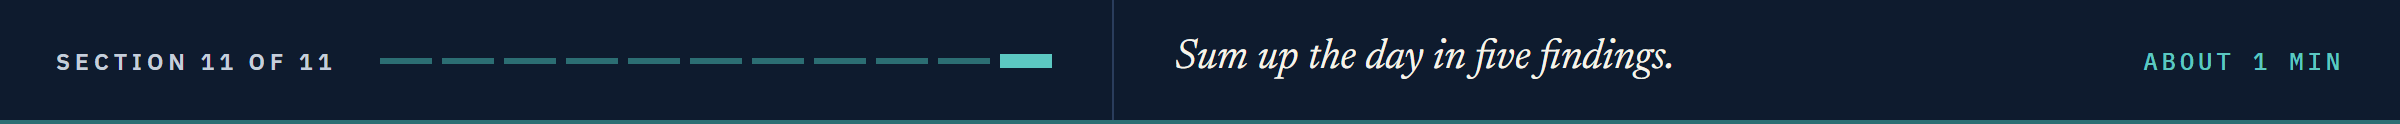

# Insights and Conclusion

`acf` is the textbook autocorrelation; `.autocorr` is a close cousin with two means.

A bar counts only against 1.96 / sqrt(n), and white noise puts about one in twenty outside.

The 10 Yr's daily change has 4 of 40 bars outside, a count one noise series in eight reaches; the squares have many times more, on every series.

The grid names an AR order by where the PACF cuts off, an MA order by where the ACF cuts off, and an ARMA when both decay.

Ljung-Box rejects three of the five changes at 10 lags; the 10 Yr's rejection rests mostly on lag 9, which holds only in the later years.

**Day 5 fits AR and ARIMA models to these changes and scores them walk-forward against the last value carried forward.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Compute an autocorrelation by hand and with `acf`, and say how `.autocorr` differs.
* Draw an ACF and a PACF with `plot_acf` and `plot_pacf`, and say which bars lie outside the band.
* Measure what white noise alone puts outside the band.
* Compute a partial autocorrelation as the last coefficient of a regression on lags.
* Simulate AR, MA and ARMA processes with `ArmaProcess` and read an order from the identification grid.
* Run the Ljung-Box test by hand and with `acorr_ljungbox`.
* Check whether an autocorrelation holds across windows of the development years.

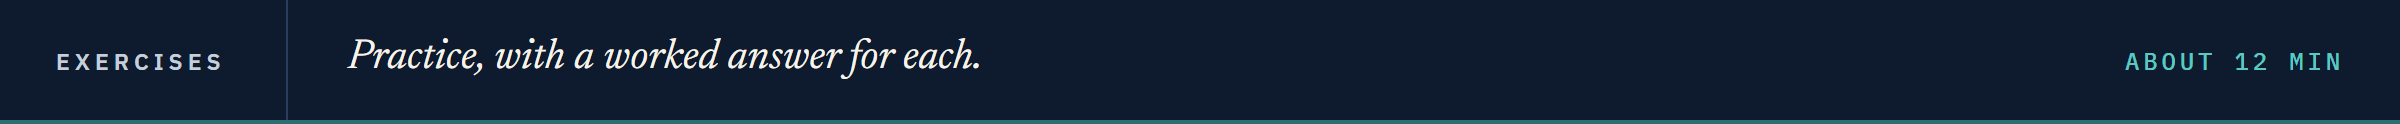

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [42]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Slope's Lag 1**

Q. Compute the lag-1 autocorrelation of the 2s10s change with `acf`, and store it in `ex1_lag1`. Is it outside the band?

In [43]:
# your code here
ex1_lag1 = ...

In [44]:
check("Exercise 1 the 2s10s change's lag-1 autocorrelation", ex1_lag1, -0.021864360907443443)

Exercise 1 the 2s10s change's lag-1 autocorrelation: not attempted yet


### Exercise 2

**Q as a Function**

Q. Write `ljung_box_q(values, lags)`, which returns the Ljung-Box Q of an array at `lags` lags from its `acf`, and store `ljung_box_q(values, 10)` in `ex2_q`.

In [45]:
# your code here
ex2_q = ...

In [46]:
check("Exercise 2 the 10 Yr's Q at 10 lags", ex2_q, 20.809645078667298)

Exercise 2 the 10 Yr's Q at 10 lags: not attempted yet


### Exercise 3

**The 2 Yr's Lag 1, Year by Year**

`.rolling(252).corr(other)` gives the correlation of two columns over each trailing window of 252 dates.

Q. Compute the 2 Yr change's correlation with itself one row before over each trailing window of 252 dates. Store the lowest value in `ex3_lowest` and the last date of its window, as text such as `"2015-01-05"`, in `ex3_date`.

In [47]:
# your code here
ex3_lowest = ...
ex3_date = ...

In [48]:
check("Exercise 3 the lowest trailing lag-1 correlation", ex3_lowest, -0.41617097855707796)
check("Exercise 3 the window's last date", ex3_date, "2021-06-11")

Exercise 3 the lowest trailing lag-1 correlation: not attempted yet
Exercise 3 the window's last date: not attempted yet


### Exercise 4: AI check

**The Band That Was Too Wide**

You asked an AI assistant for a function that lists the lags where a series has memory.
This came back.
It runs.
Test it, then find the one bug.

In [49]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def memory_lags(series, nlags=20):
    """The lags from 1 to nlags whose autocorrelation lies outside the 95 percent band."""
    bars = acf(series, nlags=nlags)[1:]
    band = 1.96 / np.sqrt(nlags)
    return [k for k in range(1, nlags + 1) if abs(bars[k - 1]) > band]

print("Memory in the 10 Yr's change at lags:", memory_lags(values))

Memory in the 10 Yr's change at lags: []


In [50]:
# the test: an AR(1) with phi 0.3 has an autocorrelation of 0.3 at lag 1, far outside any band on 2,000 values
test_values = ArmaProcess(ar=[1, -0.3], ma=[1]).generate_sample(
    nsample=2000, distrvs=np.random.default_rng(SEED).standard_normal, burnin=100)
assert 1 in memory_lags(test_values), "lag 1 of an AR(1) with phi 0.3 not found"

AssertionError: lag 1 of an AR(1) with phi 0.3 not found

Q. Fix the function, and store the lags it finds for `test_values` in `ex4_lags`.

In [51]:
# your code here
ex4_lags = ...

In [52]:
check("Exercise 4 the lags with memory", ex4_lags, [1, 2])

Exercise 4 the lags with memory: not attempted yet


## Congratulations!

You measured how much a daily change remembers, by hand and with statsmodels.
You set the band a bar must clear, watched noise clear it one time in twenty, and failed to pick the real ACF out of a lineup.
You found that the sign of a move forgets and its size remembers, on every series.
You read AR, MA and ARMA orders from the grid, and weighed forty bars at once with Ljung-Box.
In Day 5 you fit those models to the changes and score them against the last value carried forward.

[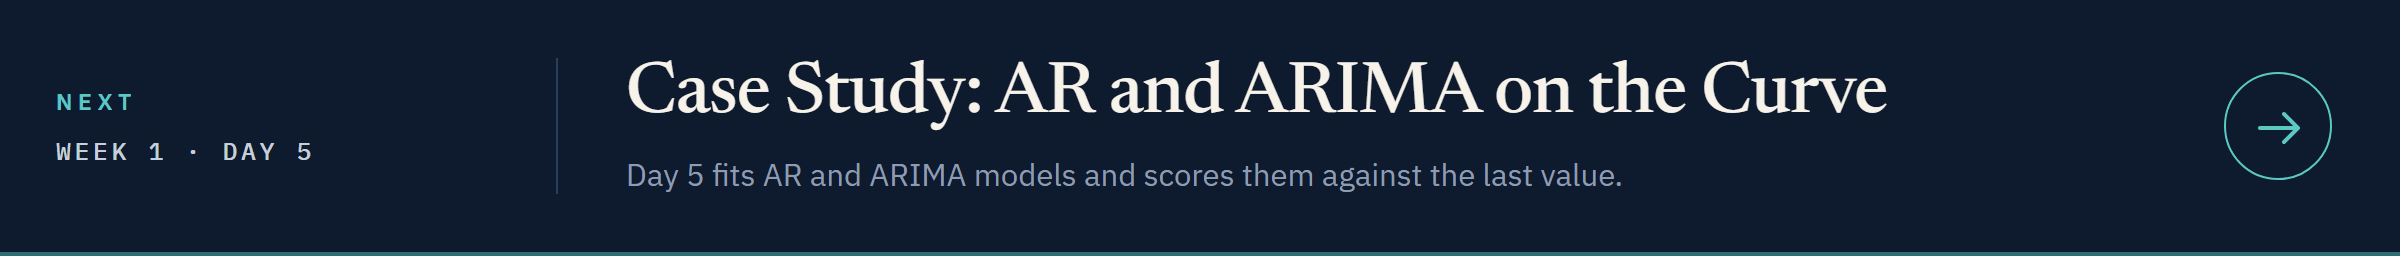](../day5/05_case_study_ar_and_arima_on_the_curve.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day5/05_case_study_ar_and_arima_on_the_curve.ipynb)